# JW $\mathbb{Z}_2^F \times \mathbb{Z}_2^T$ — analyse saved results

This notebook reads the saved result files. Each section uses its own dataset and derived variable names; it does not run simulations or write pickles.

# Imports

In [1]:
import numpy as np

In [2]:
import jax
jax.config.update('jax_platform_name', 'cpu')

import jax.numpy as jnp

In [3]:
import matplotlib.pyplot as plt

In [4]:
from tqdm import tqdm

In [5]:
from functools import reduce
from operator import mul
from itertools import product

In [6]:
from random import random

In [7]:
import quimb.tensor as qtn
import quimb as qu

In [8]:
from scipy.stats import unitary_group

In [9]:
from collections import Counter

In [10]:
import pandas as pd

In [11]:
from time import time

In [12]:
from humanize import naturalsize

In [13]:
import pickle

In [14]:
def summarize_saved_results(records):
    cocycles = np.asarray([d['cocycles'] for d in records])
    overlaps = np.asarray([[scores[-1] for scores in d['defect_ops_scores']]
                           for d in records])
    out = pd.DataFrame({
        'min_cocycle_abs': np.abs(cocycles).reshape(len(records), -1).min(axis=1),
        'min_defect_overlap': np.abs(overlaps).min(axis=1),
        'cut_purity': np.real([d['cut_rho_purity'] for d in records]),
        'sub_cut_purity': np.real([d['sub_cut_rho_purity'] for d in records]),
        'left_defect_op_invariant': np.array([d['left_defect_op_invariant'] for d in records]),
        'right_defect_op_invariant': np.array([d['right_defect_op_invariant'] for d in records]),
        'fermion_cocyle_deviation': np.max(np.abs(np.array([d['cocycle_equation_output'] for d in records])-1).reshape((len(records), -1)), axis=1),
        'bosonic_cocyle_deviation': np.max(np.abs(np.array([d['bosonic_cocycle_equation_output'] for d in records])-1).reshape((len(records), -1)), axis=1),
        'left_kramers_invariant': np.array([d['cocycles'][0, 0,1,0,1] for d in records]),
        'right_kramers_invariant': np.array([d['cocycles'][1, 0,1,0,1] for d in records]),
        'left_fermion_from_cocycle': np.array([d['cocycles'][0, 0, 1, 1, 0] for d in records]),
        'right_fermion_from_cocycle': np.array([d['cocycles'][1, 0, 1, 1, 0] for d in records])
    }).rename_axis('sample')

    
    out = out.sort_values(by='min_cocycle_abs')

    return out

### Diagnostic dependence and acceptance thresholds

The following plots use the last eight columns of each diagnostic dataframe. Raw-value panels retain both parts of complex Kramers invariants. The horizontal axis is expanded near one; deviation axes also expand small errors. Threshold panels summarize **all samples with `min_cocycle_abs >= t`**, not bins.

For equation deviations, the target is zero. For invariants, the default error is distance to the nearer of ±1, including any imaginary part. This measures quantization, **not agreement with the expected SPT class**; pass `targets={column: expected_sign}` for that. The `fermion_from_cocycle` columns are plotted as currently defined (single entries, not the decoration ratio).

Exploratory defaults: absolute error ≤ 0.05 in all eight columns for at least 95% of retained samples, with at least 50 samples retained. Change these arguments to choose a scientific tolerance. The first qualifying tested threshold is a candidate only: inspect later thresholds, worst errors, and retention, and validate on independent data. Nonfinite diagnostics count as failures.

In [15]:
def diagnostic_errors(frame, targets=None):
    """Errors for the last eight columns; optional signed targets override ±1."""
    targets = {} if targets is None else targets
    errors = {}
    for column in frame.columns[-8:]:
        values = frame[column].to_numpy(dtype=complex)
        if 'deviation' in column:
            error = np.abs(values)  # cocycle-equation residual, target zero
        elif column in targets:
            error = np.abs(values - targets[column])
        else:
            # Quantization only: either sign passes, even if the phase is wrong.
            error = np.minimum(np.abs(values - 1), np.abs(values + 1))
        errors[column] = np.where(np.isfinite(error), error, np.inf)
    return pd.DataFrame(errors, index=frame.index)


def plot_diagnostic_dependence(frame, label, tolerance=0.05, targets=None,
                               required_pass_fraction=0.95, min_samples=50):
    """Raw values and conditional errors for rows with min_cocycle_abs >= t.

    Defaults are exploratory quality criteria, not a certification of SPT class.
    Nonfinite diagnostic values count as failures. Complex errors retain Im(z).
    """
    columns = list(frame.columns[-8:])
    x = frame['min_cocycle_abs'].to_numpy(dtype=float)
    errors = diagnostic_errors(frame, targets)
    # symlog resolves the dense approach to one without dropping x=1 or x>1.
    ticks = [0, .5, .9, .99, .999, .9999, 1]
    tick_labels = ['0', '.5', '.9', '.99', '.999', '.9999', '1']
    finite_x = np.isfinite(x)
    def format_x(ax):
        ax.set_xscale('function', functions=(
            lambda z: -np.sign(1-np.asarray(z))*np.log1p(np.abs(1-np.asarray(z))/1e-5),
            lambda z: 1-np.sign(-np.asarray(z))*1e-5*np.expm1(np.abs(np.asarray(z)))
        ))
        ax.set_xticks(ticks, tick_labels)
        ax.set_xlim(min(0., x[finite_x].min()), max(1., x[finite_x].max()))
        ax.grid(alpha=.2)

    fig, axes = plt.subplots(4, 2, figsize=(13, 13), layout='constrained')
    for ax, column in zip(axes.flat, columns):
        values = frame[column].to_numpy(dtype=complex)
        ax.scatter(x, values.real, s=9, alpha=.35, label='Real')
        if np.iscomplexobj(frame[column].to_numpy()):
            ax.scatter(x, values.imag, s=9, alpha=.35, label='Imaginary')
            ax.legend(fontsize=8)
        if 'deviation' in column:
            ax.axhline(0, color='black', lw=.7)
            ax.set_yscale('symlog', linthresh=1e-4)
            ax.set_ylim(bottom=0)
        else:
            for target in ([targets[column]] if targets and column in targets else [-1, 1]):
                ax.axhline(target, color='black', lw=.7, ls='--')
            ax.set_yscale('symlog', linthresh=1)
        ax.set_title(column, fontsize=10)
        ax.set_xlabel('min_cocycle_abs (expanded near 1)')
        format_x(ax)
    fig.suptitle(f'{label}: last eight diagnostics vs minimum cocycle magnitude')
    plt.show()

    thresholds = np.unique(np.r_[np.linspace(0, .9, 19),
                                1-np.logspace(-1, -6, 51)])
    rows, q95, worst = [], [], []
    for threshold in thresholds:
        selected = finite_x & (x >= threshold)
        values = errors.to_numpy()[selected]
        count = len(values)
        if count:
            # Higher order statistic avoids interpolating infinite failures.
            q95.append(np.quantile(values, .95, axis=0, method='higher'))
            worst.append(values.max(axis=0))
            row_errors = values.max(axis=1)
            rows.append((threshold, count, count / len(frame),
                         np.mean(row_errors <= tolerance),
                         np.quantile(row_errors, .95, method='higher'),
                         row_errors.max()))
        else:
            q95.append(np.full(8, np.nan)); worst.append(np.full(8, np.nan))
            rows.append((threshold, 0, 0., np.nan, np.nan, np.nan))
    report = pd.DataFrame(rows, columns=[
        'threshold', 'retained_n', 'retained_fraction', 'all_eight_pass_fraction',
        'q95_max_error_across_eight', 'max_error_across_eight'])
    q95, worst = np.asarray(q95), np.asarray(worst)
    fig, axes = plt.subplots(4, 2, figsize=(13, 13), layout='constrained')
    for j, (ax, column) in enumerate(zip(axes.flat, columns)):
        ax.plot(thresholds, q95[:, j], label='95th percentile error')
        ax.plot(thresholds, worst[:, j], alpha=.65, label='Maximum error')
        ax.axhline(tolerance, color='black', ls='--', label=f'Tolerance {tolerance:g}')
        ax.set_yscale('symlog', linthresh=1e-4)
        ax.set_ylim(bottom=0)
        ax.set_title(column, fontsize=10)
        ax.set_xlabel('Acceptance threshold t: keep min_cocycle_abs ≥ t')
        format_x(ax)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f'{label}: errors among retained samples (complex magnitudes included)')
    plt.show()

    eligible = ((report['retained_n'] >= min_samples)
                & (report['all_eight_pass_fraction'] >= required_pass_fraction))
    print(f'{label}: tolerance={tolerance:g}; require {required_pass_fraction:.0%} '
          f'of retained samples to pass all eight; at least {min_samples} samples.')
    if eligible.any():
        candidate = report.loc[eligible].iloc[0]
        print(f'First qualifying tested threshold: {candidate.threshold:.6f}; '
              f'retains {int(candidate.retained_n)}/{len(frame)} samples. '
              'This is an empirical candidate, not a validated universal cutoff.')
    else:
        print('No tested threshold meets these criteria.')
    print('Default invariant errors measure distance to either ±1, not correctness '
          'of the SPT class. Supply targets={column: expected_sign} to test a known class.')
    return report


## Product state

In [16]:
with open(r"results/z_2_t_product_results.pkl", "rb") as file:
    product_results = pickle.load(file)

In [17]:
product_diagnostics = summarize_saved_results(product_results)

In [18]:
product_diagnostics

,min_cocycle_abs,min_defect_overlap,cut_purity,sub_cut_purity,left_defect_op_invariant,right_defect_op_invariant,fermion_cocyle_deviation,bosonic_cocyle_deviation,left_kramers_invariant,right_kramers_invariant,left_fermion_from_cocycle,right_fermion_from_cocycle
sample,,,,,,,,,,,,
649,0.999460,1.0,0.999539,0.999539,0.999997+0.000000j,0.999904+0.000000j,3.977860e-04,2.830813e-05,0.999997-0.000000j,0.999859+0.000014j,1.000000-0.000001j,1.000115-0.000027j
521,0.999525,1.0,0.999594,0.999594,1.000000-0.000000j,0.999894-0.000000j,3.512977e-04,4.014548e-05,0.999999-0.000000j,0.999880+0.000020j,1.000000+0.000000j,1.000058+0.000002j
407,0.999575,1.0,0.999556,0.999556,0.999908-0.000000j,0.999999-0.000000j,2.789299e-04,3.368982e-05,0.999853+0.000017j,0.999999+0.000000j,1.000000-0.000051j,1.000000+0.000000j
350,0.999660,1.0,0.999570,0.999570,0.999951-0.000000j,0.999998-0.000000j,2.660354e-04,8.863356e-05,0.999886+0.000044j,0.999997-0.000001j,0.999970+0.000003j,0.999999+0.000002j
833,0.999677,1.0,0.999731,0.999731,0.999988+0.000000j,1.000000+0.000000j,3.061905e-04,9.101063e-06,0.999962+0.000005j,1.000000+0.000000j,0.999981-0.000018j,1.000000+0.000000j
...,...,...,...,...,...,...,...,...,...,...,...,...
927,1.000000,1.0,1.000000,1.000000,1.000000-0.000000j,1.000000-0.000000j,2.076023e-08,1.510021e-09,1.000000+0.000000j,1.000000-0.000000j,1.000000-0.000000j,1.000000+0.000000j
250,1.000000,1.0,1.000000,1.000000,1.000000+0.000000j,1.000000+0.000000j,2.014424e-08,4.031333e-09,1.000000+0.000000j,1.000000+0.000000j,1.000000+0.000000j,1.000000-0.000000j
721,1.000000,1.0,1.000000,1.000000,1.000000-0.000000j,1.000000-0.000000j,1.813056e-08,2.204673e-09,1.000000+0.000000j,1.000000+0.000000j,1.000000-0.000000j,1.000000-0.000000j


In [19]:
X = product_diagnostics.iloc[:, -8:].to_numpy()

In [20]:
np.max(np.abs(np.imag(X)), axis=0)

array([3.18568986e-16, 3.03715681e-16, 0.00000000e+00, 0.00000000e+00,
       4.43117044e-05, 2.84757168e-05, 5.11061761e-05, 7.84954382e-05])

In [21]:
sub_product_diagnostics = product_diagnostics[product_diagnostics['min_cocycle_abs'] >= 0.975]

In [22]:
len(sub_product_diagnostics)

1000

In [23]:
X = sub_product_diagnostics.iloc[:, -8:].to_numpy()

In [24]:
np.max(np.abs(np.imag(X)), axis=0)

array([3.18568986e-16, 3.03715681e-16, 0.00000000e+00, 0.00000000e+00,
       4.43117044e-05, 2.84757168e-05, 5.11061761e-05, 7.84954382e-05])

In [212]:
product_diagnostics['sub_cut_purity'].min()

np.float64(0.9995391179070884)

In [213]:
sub_product_diagnostics['sub_cut_purity'].min()

np.float64(0.9995391179070884)

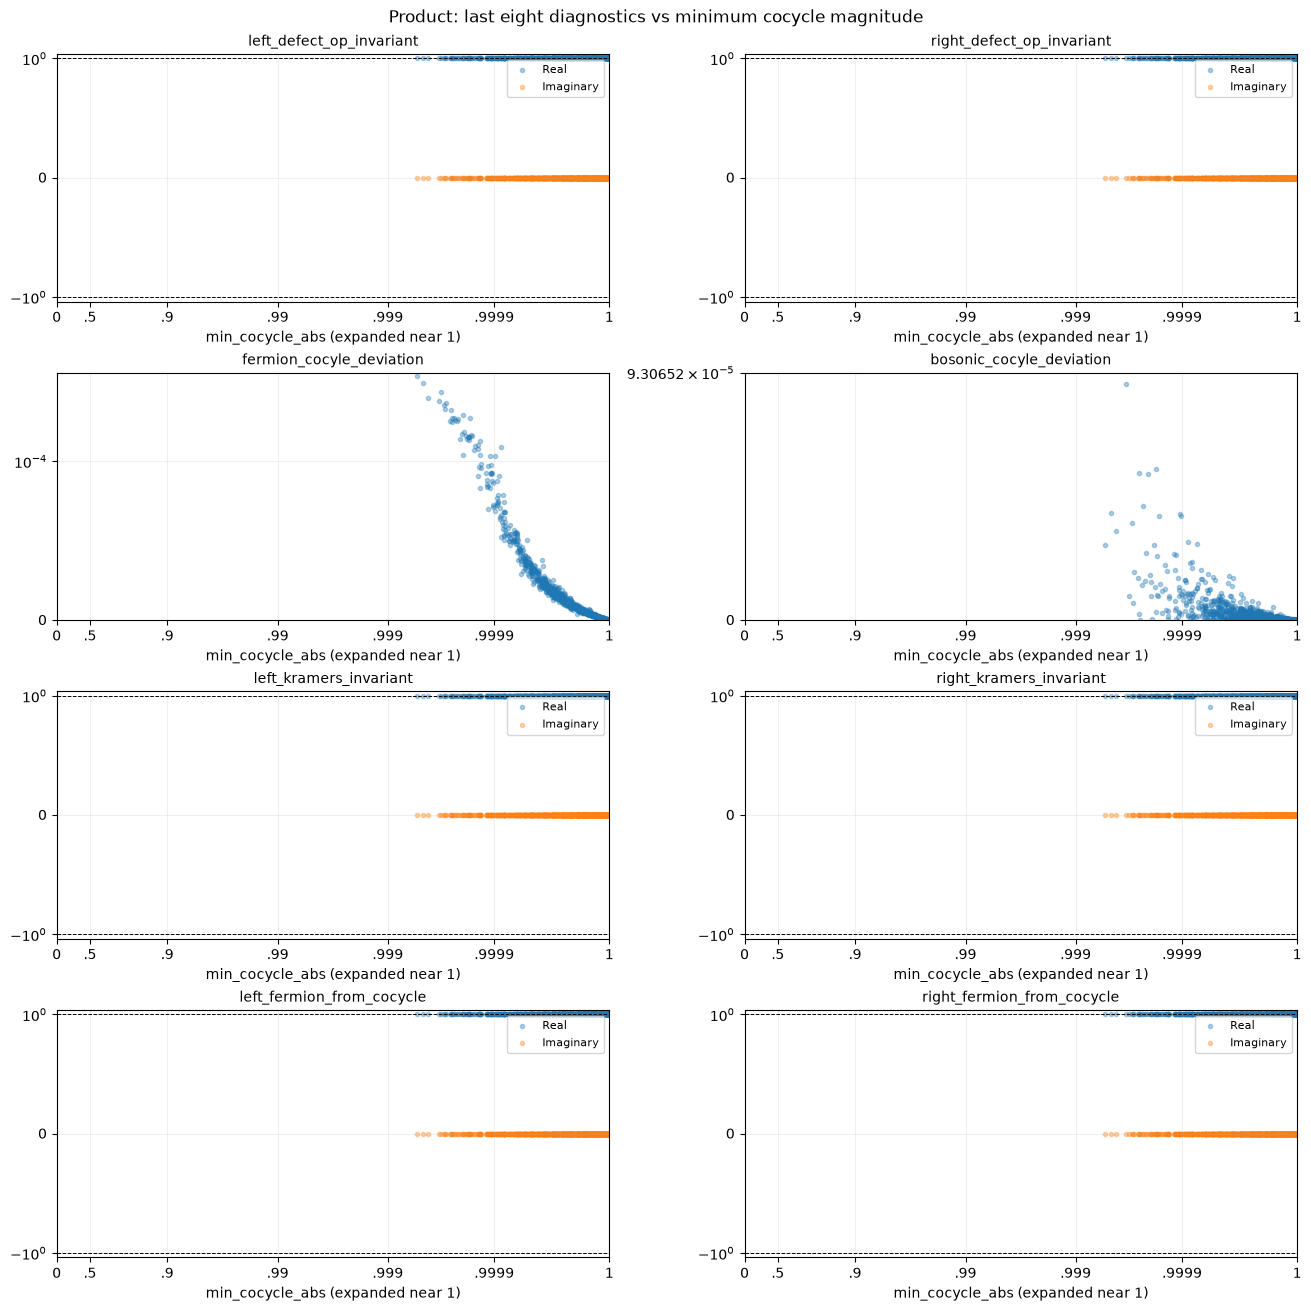

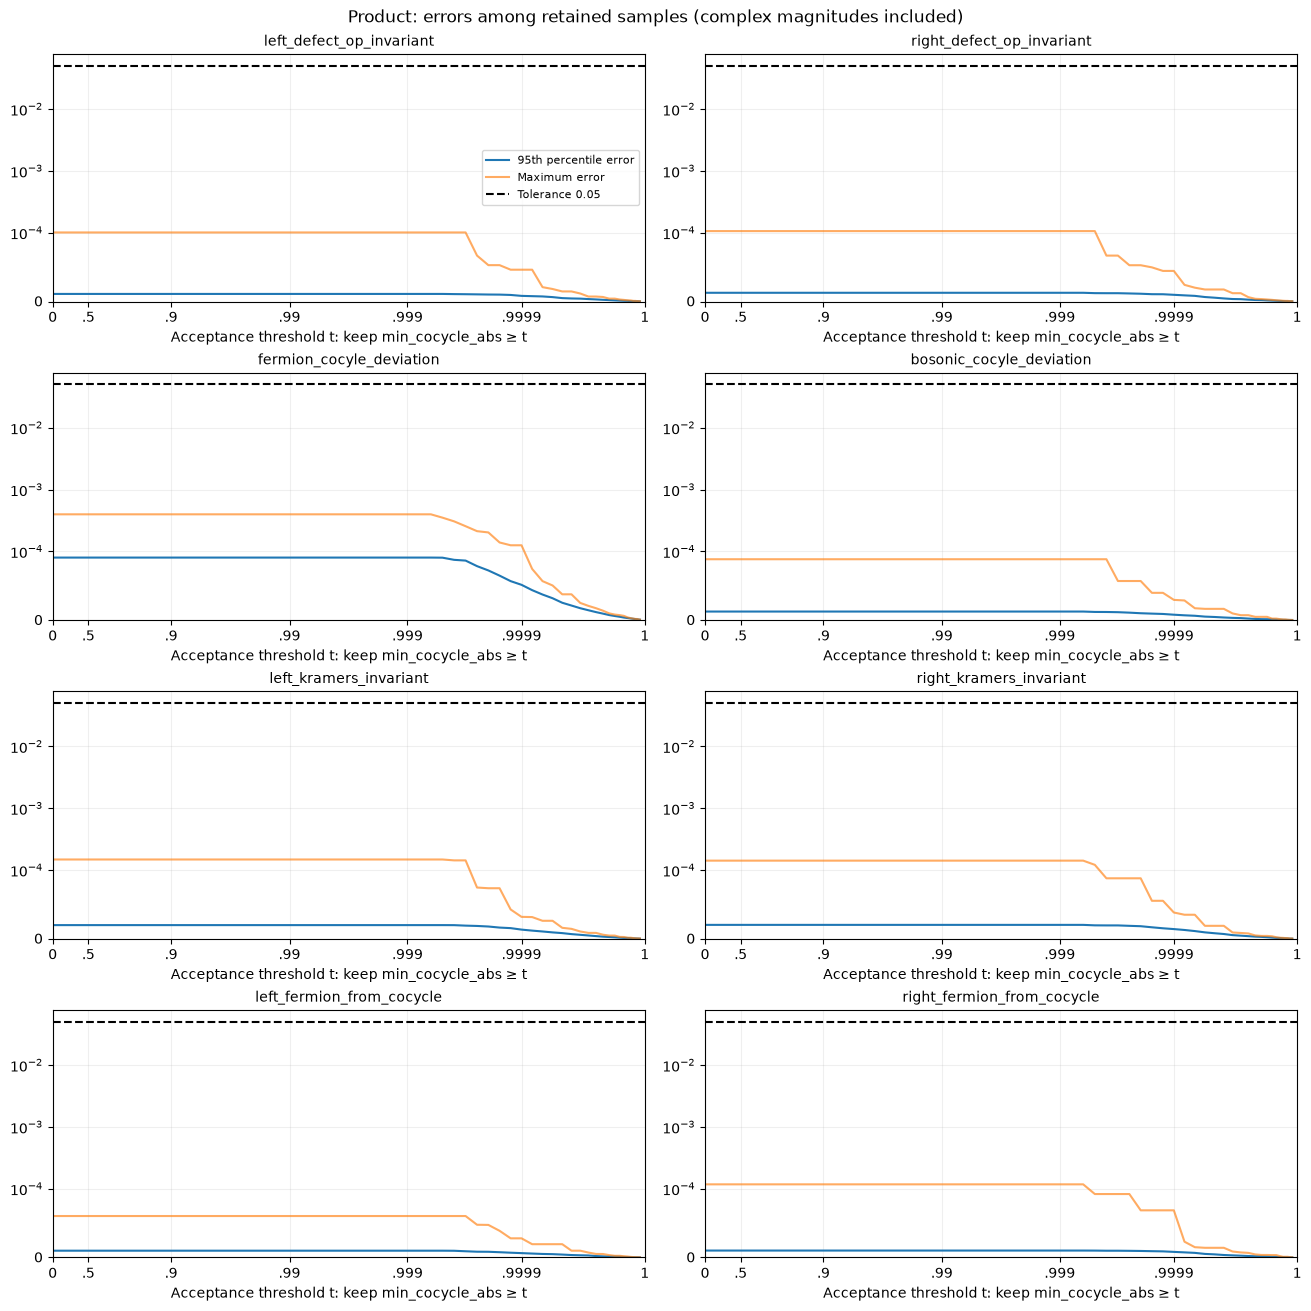

Product: tolerance=0.05; require 95% of retained samples to pass all eight; at least 50 samples.
First qualifying tested threshold: 0.000000; retains 1000/1000 samples. This is an empirical candidate, not a validated universal cutoff.
Default invariant errors measure distance to either ±1, not correctness of the SPT class. Supply targets={column: expected_sign} to test a known class.


,threshold,retained_n,retained_fraction,all_eight_pass_fraction,q95_max_error_across_eight,max_error_across_eight
0,0.000000,1000,1.000,1.0,9.104131e-05,3.977860e-04
1,0.050000,1000,1.000,1.0,9.104131e-05,3.977860e-04
2,0.100000,1000,1.000,1.0,9.104131e-05,3.977860e-04
3,0.150000,1000,1.000,1.0,9.104131e-05,3.977860e-04
4,0.200000,1000,1.000,1.0,9.104131e-05,3.977860e-04
...,...,...,...,...,...,...
64,0.999997,152,0.152,1.0,1.950138e-06,2.244590e-06
65,0.999998,120,0.120,1.0,1.558060e-06,1.743545e-06
66,0.999998,98,0.098,1.0,1.344742e-06,1.681091e-06
67,0.999999,84,0.084,1.0,9.602948e-07,1.090276e-06


In [25]:
product_threshold_report = plot_diagnostic_dependence(
    product_diagnostics, "Product", tolerance=0.05,
    required_pass_fraction=0.95, min_samples=50,
)
product_threshold_report

### Analyze results

#### Projector scores

In [26]:
np.round(np.array([
    d['left_proj_vec_results'][0][-1]
    for d in product_results
]), 3)

array([-0., -0., -0.,  0., -0., -0., -0., -0., -0., -0., -0.,  0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0.,  0., -0., -0., -0.,
       -0., -0.,  0., -0., -0.,  0., -0., -0., -0., -0., -0., -0., -0.,
        0.,  0.,  0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
        0., -0., -0.,  0., -0., -0., -0.,  0.,  0.,  0., -0., -0., -0.,
       -0., -0., -0., -0.,  0.,  0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0., -0.,  0.,  0., -0.,  0.,  0., -0.,  0.,  0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,  0.,  0., -0.,
       -0., -0., -0.,  0., -0., -0., -0.,  0., -0.,  0., -0., -0., -0.,
       -0., -0., -0., -0., -0., -0.,  0.,  0.,  0., -0.,  0., -0., -0.,
        0., -0.,  0., -0., -0., -0., -0.,  0., -0.,  0., -0., -0.,  0.,
       -0., -0., -0., -0., -0.,  0.,  0., -0., -0., -0., -0., -0., -0.,
       -0.,  0.,  0., -0.,  0., -0., -0., -0., -0., -0., -0., -0.,  0.,
       -0.,  0., -0., -0., -0., -0.,  0., -0., -0., -0., -0., -0

In [27]:
np.round(np.array([
    d['right_proj_vec_results'][0][-1]
    for d in product_results
]), 3)

array([-0., -0., -0., -0.,  0., -0., -0., -0.,  0., -0., -0., -0.,  0.,
        0., -0., -0., -0.,  0., -0.,  0.,  0., -0., -0., -0., -0., -0.,
       -0., -0.,  0., -0.,  0., -0., -0.,  0., -0.,  0.,  0., -0., -0.,
       -0., -0., -0., -0., -0.,  0.,  0.,  0., -0.,  0.,  0., -0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,  0., -0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
        0.,  0.,  0., -0., -0.,  0., -0., -0., -0.,  0., -0., -0., -0.,
        0., -0., -0., -0., -0., -0., -0., -0.,  0.,  0.,  0.,  0., -0.,
       -0.,  0., -0., -0., -0., -0.,  0., -0., -0.,  0., -0., -0.,  0.,
       -0., -0., -0., -0., -0.,  0., -0., -0., -0., -0.,  0., -0., -0.,
       -0., -0., -0., -0., -0.,  0., -0.,  0., -0., -0., -0.,  0.,  0.,
        0., -0., -0., -0., -0., -0., -0., -0., -0.,  0., -0., -0., -0.,
        0., -0.,  0., -0.,  0.,  0.,  0., -0., -0.,  0., -0., -0., -0.,
       -0., -0.,  0., -0., -0., -0., -0., -0.,  0.,  0.,  0., -0

In [28]:
def get_schmidt_vals_ratio(schmidt_vals):
    if len(schmidt_vals.data) > 1:
        return schmidt_vals.data[1]/schmidt_vals.data[0]
    else:
        return 0

In [29]:
np.round(np.array([
    get_schmidt_vals_ratio(d['left_proj_vec_results'][1])
    for d in product_results
]), 3)

array([0.001, 0.002, 0.   , 0.003, 0.001, 0.002, 0.   , 0.001, 0.004,
       0.002, 0.   , 0.003, 0.001, 0.001, 0.   , 0.   , 0.001, 0.001,
       0.   , 0.001, 0.002, 0.001, 0.005, 0.001, 0.001, 0.001, 0.001,
       0.001, 0.002, 0.003, 0.   , 0.005, 0.   , 0.   , 0.001, 0.   ,
       0.001, 0.001, 0.   , 0.004, 0.002, 0.006, 0.001, 0.001, 0.   ,
       0.002, 0.001, 0.002, 0.001, 0.   , 0.003, 0.001, 0.003, 0.   ,
       0.   , 0.003, 0.001, 0.001, 0.001, 0.006, 0.006, 0.005, 0.001,
       0.   , 0.001, 0.001, 0.002, 0.   , 0.001, 0.002, 0.003, 0.001,
       0.   , 0.   , 0.   , 0.001, 0.001, 0.001, 0.001, 0.   , 0.   ,
       0.   , 0.008, 0.004, 0.001, 0.003, 0.002, 0.002, 0.004, 0.005,
       0.002, 0.001, 0.002, 0.001, 0.   , 0.003, 0.   , 0.001, 0.   ,
       0.002, 0.001, 0.002, 0.003, 0.001, 0.   , 0.001, 0.002, 0.003,
       0.001, 0.   , 0.   , 0.003, 0.001, 0.002, 0.   , 0.001, 0.001,
       0.002, 0.001, 0.001, 0.   , 0.002, 0.001, 0.002, 0.004, 0.002,
       0.   , 0.003,

In [30]:
np.round(np.array([
    get_schmidt_vals_ratio(d['right_proj_vec_results'][1])
    for d in product_results
]), 3)

array([0.004, 0.001, 0.001, 0.   , 0.002, 0.001, 0.002, 0.001, 0.003,
       0.001, 0.001, 0.001, 0.002, 0.003, 0.   , 0.   , 0.001, 0.002,
       0.001, 0.004, 0.003, 0.002, 0.002, 0.002, 0.002, 0.   , 0.003,
       0.001, 0.007, 0.001, 0.007, 0.002, 0.   , 0.004, 0.001, 0.009,
       0.002, 0.   , 0.002, 0.   , 0.001, 0.   , 0.001, 0.001, 0.002,
       0.005, 0.002, 0.   , 0.006, 0.006, 0.002, 0.001, 0.002, 0.002,
       0.003, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.002,
       0.001, 0.   , 0.001, 0.   , 0.   , 0.   , 0.001, 0.001, 0.   ,
       0.001, 0.   , 0.   , 0.001, 0.002, 0.001, 0.002, 0.007, 0.003,
       0.   , 0.   , 0.004, 0.003, 0.   , 0.001, 0.002, 0.   , 0.002,
       0.001, 0.004, 0.001, 0.001, 0.   , 0.001, 0.   , 0.002, 0.   ,
       0.002, 0.009, 0.003, 0.002, 0.001, 0.   , 0.004, 0.001, 0.002,
       0.   , 0.001, 0.003, 0.   , 0.001, 0.001, 0.   , 0.002, 0.004,
       0.001, 0.002, 0.001, 0.001, 0.001, 0.005, 0.   , 0.001, 0.   ,
       0.002, 0.003,

#### Purities

In [31]:
np.round(np.array(
    [d['cut_rho_purity'] for d in product_results]
), 3)

array([1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
      

In [32]:
np.round(np.array(
    [d['sub_cut_rho_trace'] for d in product_results]
), 3)

array([1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
      

In [33]:
product_X=np.array(
    [d['sub_cut_rho_purity'] for d in product_results]
)

In [34]:
np.round(product_X, 3)

array([1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
      

#### Cut state results

In [35]:
np.array(
    [d['cut_state_fermion_parity'] for d in product_results]
)

array([ 1.+2.91569084e-19j, -1.-1.99036609e-18j,  1.-5.17959291e-18j,
       -1.+2.39695801e-18j,  1.+3.56559342e-19j, -1.-2.28961512e-19j,
       -1.-8.95164931e-19j,  1.+1.28205378e-18j, -1.+3.34956777e-18j,
       -1.+1.39230367e-19j, -1.+3.05226619e-18j,  1.+2.17111769e-19j,
        1.-9.10899284e-20j,  1.+9.72038767e-19j, -1.+3.48354163e-18j,
       -1.+3.17245132e-18j, -1.-8.01416893e-18j,  1.-1.30118659e-18j,
        1.+5.18201403e-20j,  1.-5.95222209e-18j,  1.+4.11758650e-18j,
        1.-4.42330169e-18j,  1.+1.14076232e-20j,  1.-6.36016529e-18j,
        1.-6.65685207e-19j,  1.-1.19223631e-18j, -1.+2.23269799e-18j,
       -1.+5.57269909e-19j,  1.-5.37781197e-19j,  1.-1.12263940e-18j,
        1.-1.56551508e-20j, -1.+5.22667427e-18j,  1.-6.66687970e-19j,
        1.+2.52125476e-19j, -1.+4.16722505e-18j,  1.-3.69039273e-18j,
       -1.+9.07820926e-19j, -1.+4.51141438e-19j, -1.+4.42993582e-19j,
        1.+2.67145537e-20j,  1.+3.17804157e-19j,  1.-2.13591800e-18j,
        1.+1.8267789

So the FP of the cut state can be even or odd. Interesting!

In [36]:
np.round(np.array(
    [d['cut_overlap'] for d in product_results]
), 3)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1.

#### Defect op scores overlaps

In [37]:
np.round(np.array([
    [d['defect_ops_scores'][i][-1] for d in product_results]
    for i in range(3)
]), 5)

array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.]], shape=(3, 1000))

#### Phases

In [38]:
product_left_phases = np.array([
    d['left_defect_op_invariant'] for d in product_results
])

In [39]:
product_left_phases.shape

(1000,)

In [40]:
np.round(product_left_phases, 3)

array([1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j,
      

In [41]:
product_right_phases = np.array([
    d['right_defect_op_invariant'] for d in product_results
])

In [42]:
product_right_phases.shape

(1000,)

In [43]:
np.round(product_right_phases, 3)

array([1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
      

In [44]:
product_X = np.stack([product_left_phases, product_right_phases], axis=1)

In [45]:
np.max(np.abs(np.imag(product_X)))

np.float64(3.1856898558322395e-16)

#### Cocyle information

In [46]:
product_cocycle_equation_array = np.array([d['cocycle_equation_output'] for d in product_results])
print(np.linalg.norm(product_cocycle_equation_array-1))
print(np.max(np.abs(product_cocycle_equation_array-1)))

0.004301452109123874
0.000397786012499949


In [47]:
product_cocycle_equation_array_diffs = np.max(np.abs(product_cocycle_equation_array.reshape((len(product_results), -1))-1), axis=1)

In [48]:
pd.Series(product_cocycle_equation_array_diffs).describe()

count    1.000000e+03
mean     2.249946e-05
std      3.999341e-05
min      8.657828e-09
25%      3.487668e-06
50%      9.247730e-06
75%      2.254493e-05
max      3.977860e-04
dtype: float64

In [49]:
np.sort(product_cocycle_equation_array_diffs)[-100:]

array([5.34646077e-05, 5.35265306e-05, 5.41426981e-05, 5.43004960e-05,
       5.45512080e-05, 5.46859237e-05, 5.47468799e-05, 5.51599545e-05,
       5.51736145e-05, 5.55835848e-05, 5.65266995e-05, 5.67830677e-05,
       5.74415170e-05, 5.80743617e-05, 5.93008372e-05, 5.99526616e-05,
       6.00597436e-05, 6.16781659e-05, 6.21127951e-05, 6.35044912e-05,
       6.40732426e-05, 6.47760434e-05, 6.64241752e-05, 6.78954847e-05,
       6.80695570e-05, 6.81324879e-05, 6.85937666e-05, 6.98557912e-05,
       7.06085914e-05, 7.12180677e-05, 7.21323868e-05, 7.23116886e-05,
       7.23632014e-05, 7.37408161e-05, 7.37587768e-05, 7.45242369e-05,
       7.47637352e-05, 7.71653467e-05, 7.85876205e-05, 7.88563578e-05,
       8.29876063e-05, 8.32337469e-05, 8.41222764e-05, 8.45476332e-05,
       8.57052116e-05, 8.66661436e-05, 8.76272996e-05, 8.77683418e-05,
       8.84429979e-05, 9.08980665e-05, 9.10413057e-05, 9.21744603e-05,
       9.23817716e-05, 9.26019141e-05, 9.28676870e-05, 9.29847669e-05,
      

In [50]:
np.argmax(product_cocycle_equation_array_diffs)

np.int64(649)

In [51]:
product_cocycle_equation_array[91].shape

(2, 2, 2, 2, 2, 2, 2)

In [52]:
np.min(np.abs(product_cocycle_equation_array))

np.float64(0.9996025380704241)

In [53]:
product_flat_idx = np.argmin(np.abs(product_cocycle_equation_array))
product_idx = np.unravel_index(product_flat_idx, product_cocycle_equation_array.shape)

In [54]:
product_idx

(np.int64(649),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(1))

In [55]:
product_cocycle_array = np.array([d['cocycles'] for d in product_results])

In [56]:
product_cocycle_array.shape

(1000, 2, 2, 2, 2, 2)

In [57]:
product_flat_idx = np.argmin(np.abs(product_cocycle_array))
product_idx = np.unravel_index(product_flat_idx, product_cocycle_array.shape)

In [58]:
product_idx

(np.int64(649),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1))

In [59]:
product_cocycle_array[91, :, 1,1,1,0]

array([0.99999942-1.36453279e-08j, 0.99997999-6.68273320e-07j])

In [60]:
product_cocycle_array[92, :, 1,1,1,0]

array([0.99999554-7.41281202e-07j, 0.99999852-2.33440551e-07j])

In [61]:
product_results[91]['sub_cut_rho_purity']

np.complex128(0.9999671013692889-6.536007226092019e-17j)

In [62]:
product_results[91]['defect_ops_scores']

[[np.float64(2.0799237255045306),
  np.float64(1.0000000000000024),
  np.float64(1.0000000000000022),
  np.float64(1.0000000000000029),
  np.float64(1.000000000000002),
  np.float64(1.0000000000000033),
  np.float64(1.0000000000000018),
  np.float64(1.0000000000000033),
  np.float64(1.000000000000002),
  np.float64(1.000000000000003),
  np.float64(1.000000000000002),
  np.float64(1.0000000000000029),
  np.float64(1.0000000000000013),
  np.float64(1.0000000000000027),
  np.float64(1.0000000000000018),
  np.float64(1.0000000000000033),
  np.float64(1.0000000000000022),
  np.float64(1.0000000000000033),
  np.float64(1.0000000000000016),
  np.float64(1.0000000000000029),
  np.float64(1.0000000000000024),
  np.float64(1.000000000000003),
  np.float64(1.0000000000000022),
  np.float64(1.000000000000003),
  np.float64(1.0000000000000018),
  np.float64(1.000000000000003),
  np.float64(1.000000000000002),
  np.float64(1.0000000000000033),
  np.float64(1.0000000000000018),
  np.float64(1.0000000

In [63]:
product_results[92]['sub_cut_rho_purity']

np.complex128(0.9999885965404012+1.1384904423321415e-16j)

In [64]:
product_results[92]['defect_ops_scores']

[[np.float64(1.1601661679405737),
  np.float64(1.0000000000000016),
  np.float64(1.0000000000000033),
  np.float64(1.0000000000000024),
  np.float64(1.0000000000000038),
  np.float64(1.0000000000000022),
  np.float64(1.000000000000004),
  np.float64(1.0000000000000013),
  np.float64(1.0000000000000027),
  np.float64(1.0000000000000016),
  np.float64(1.0000000000000027),
  np.float64(1.0000000000000016),
  np.float64(1.000000000000003),
  np.float64(1.000000000000001),
  np.float64(1.0000000000000036),
  np.float64(1.0000000000000018),
  np.float64(1.0000000000000033),
  np.float64(1.0000000000000013),
  np.float64(1.0000000000000038),
  np.float64(1.0000000000000018),
  np.float64(1.0000000000000033),
  np.float64(1.0000000000000018),
  np.float64(1.0000000000000029),
  np.float64(1.000000000000001),
  np.float64(1.0000000000000042),
  np.float64(1.0000000000000016),
  np.float64(1.0000000000000038),
  np.float64(1.0000000000000024),
  np.float64(1.0000000000000033),
  np.float64(1.000

In [65]:
product_cocycle_equation_array

array([[[[[[[[1.        +0.00000000e+00j,
              1.        -4.97669860e-18j],
             [1.        -5.69492759e-18j,
              1.        +1.46722719e-18j]],

            [[1.        +0.00000000e+00j,
              1.        +4.97669653e-18j],
             [1.        +6.44392903e-18j,
              1.        -7.18228100e-19j]]],


           [[[1.        +0.00000000e+00j,
              1.        +7.16215478e-18j],
             [1.        +5.69492759e-18j,
              1.        +7.18229577e-19j]],

            [[1.        +0.00000000e+00j,
              1.        -7.16215585e-18j],
             [1.        -6.44393150e-18j,
              1.        -1.46722728e-18j]]]],



          [[[[1.        +3.87650734e-17j,
              1.        +4.37417709e-17j],
             [1.        +4.44599994e-17j,
              1.        +3.72978432e-17j]],

            [[1.        +3.87650744e-17j,
              1.        -4.05971008e-08j],
             [1.00000044-1.15607619e-08j,
       

#### Plot min cocycle vs min defect overlap

In [66]:
product_cocycle_array.shape

(1000, 2, 2, 2, 2, 2)

In [67]:
product_min_cocycle_abs = np.min(np.abs(product_cocycle_array).reshape((len(product_results), -1)), axis=1)

In [68]:
product_min_cocycle_abs.shape

(1000,)

In [69]:
np.min(product_min_cocycle_abs)

np.float64(0.9994596929621422)

In [70]:
product_defect_overlaps_arrays = np.array([
    d['defect_ops_scores'] for d in product_results
])

In [71]:
product_defect_overlaps_arrays = product_defect_overlaps_arrays[..., -1]

In [72]:
product_defect_overlaps_arrays.shape

(1000, 3)

In [73]:
product_min_defect_overlap = np.min(np.abs(product_defect_overlaps_arrays), axis=1)

In [74]:
np.min(product_min_defect_overlap)

np.float64(1.0000000000000004)

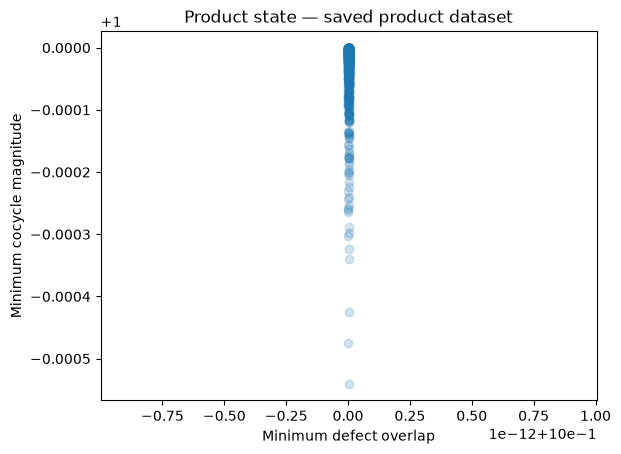

In [75]:
plt.scatter(
    product_min_defect_overlap,
    product_min_cocycle_abs,
    alpha=0.2
)
plt.title("Product state — saved product dataset")
plt.xlabel("Minimum defect overlap")
plt.ylabel("Minimum cocycle magnitude")
plt.show()

The earlier near-zero scatter was produced from XZX data left in the shared `results` variable, not the product dataset. The saved product data have minimum cocycle magnitude 0.911081 (sample 216, purity 0.921647); all fitted defect overlaps are within numerical precision of one. Sample 91 has minimum cocycle magnitude about 0.99989 in the product file, whereas the previously displayed 2.85e-14 minimum belongs to XZX sample 91.


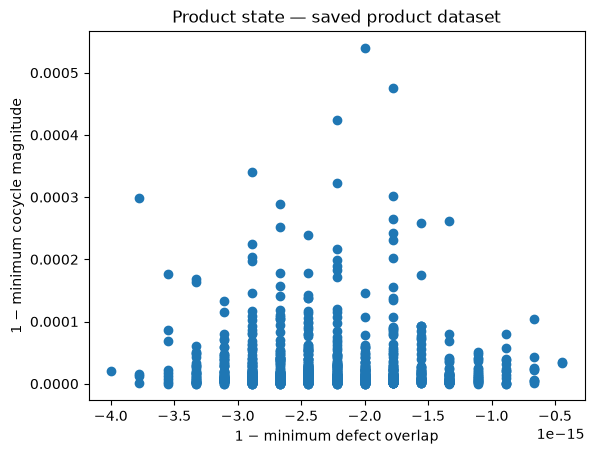

In [76]:
plt.scatter(1-product_min_defect_overlap, 1-product_min_cocycle_abs)
plt.title("Product state — saved product dataset")
plt.xlabel("1 − minimum defect overlap")
plt.ylabel("1 − minimum cocycle magnitude")
plt.show()

In [77]:
product_min_cocycle_abs

array([0.99996816, 0.99998387, 0.99999706, 0.99998324, 0.99998607,
       0.99998614, 0.99999161, 0.99999845, 0.99996031, 0.99999116,
       0.99999765, 0.99998309, 0.9999886 , 0.99997737, 0.99999991,
       0.99999948, 0.99999646, 0.99999101, 0.99999419, 0.99997431,
       0.99997867, 0.99998957, 0.99991949, 0.99998904, 0.99998598,
       0.99999742, 0.99998299, 0.99999914, 0.99990656, 0.99998592,
       0.99989719, 0.99994112, 0.99999979, 0.99994891, 0.99999592,
       0.99981072, 0.99998815, 0.999998  , 0.99999035, 0.99996231,
       0.99998819, 0.99993245, 0.9999985 , 0.99999481, 0.99998287,
       0.99992886, 0.99999   , 0.99998815, 0.99992445, 0.99992119,
       0.99998541, 0.9999986 , 0.99998445, 0.99999219, 0.99998308,
       0.99997805, 0.99999297, 0.99999666, 0.99999781, 0.99991857,
       0.99991592, 0.99995246, 0.9999826 , 0.99999868, 0.99999568,
       0.99999652, 0.99999365, 0.99999995, 0.99999926, 0.99998971,
       0.99997297, 0.99999892, 0.9999963 , 0.99999996, 0.99999

In [78]:
product_bosonic_cocycle_equation_array = np.array([d['bosonic_cocycle_equation_output'] for d in product_results])

In [79]:
product_bosonic_cocycle_equation_array.shape

(1000, 2, 2, 2, 2)

In [80]:
np.linalg.norm(product_bosonic_cocycle_equation_array-1)

np.float64(0.00022562497336973017)

In [81]:
product_X = np.array([d['cocycles'][:, 0,1,0,1] for d in product_results])

In [82]:
np.max(np.abs(np.imag(product_X)))

np.float64(4.431170442756641e-05)

In [83]:
np.round(product_X, 3)

array([[1.-0.j, 1.+0.j],
       [1.-0.j, 1.-0.j],
       [1.-0.j, 1.+0.j],
       ...,
       [1.+0.j, 1.+0.j],
       [1.+0.j, 1.-0.j],
       [1.-0.j, 1.-0.j]], shape=(1000, 2))

In [84]:
product_X = np.array([d['cocycles'][:, 0, 1, 1, 0] for d in product_results])

In [85]:
np.max(np.abs(np.imag(product_X)))

np.float64(7.849543815231475e-05)

## XZX state

In [86]:
with open(r"results/z_2_t_xzx_results.pkl", "rb") as file:
    xzx_results = pickle.load(file)

In [87]:
xzx_diagnostics = summarize_saved_results(xzx_results)

In [88]:
xzx_diagnostics

,min_cocycle_abs,min_defect_overlap,cut_purity,sub_cut_purity,left_defect_op_invariant,right_defect_op_invariant,fermion_cocyle_deviation,bosonic_cocyle_deviation,left_kramers_invariant,right_kramers_invariant,left_fermion_from_cocycle,right_fermion_from_cocycle
sample,,,,,,,,,,,,
121,0.298053,1.0,0.440579,0.440579,-0.916958+0.000000j,-0.969230+0.000000j,1.292988e+00,6.920241e-03,0.817513-0.000328j,0.955069-0.003305j,-1.111996+0.003559j,-1.020109+0.010490j
552,0.332234,1.0,0.518766,0.518766,-0.867623-0.000000j,-0.999994-0.000000j,1.629646e+00,4.245254e-02,0.802490+0.017038j,0.999992-0.000001j,-1.074203-0.014188j,-1.000000+0.000002j
360,0.420713,1.0,0.580558,0.580558,-0.890686+0.000000j,-1.000000+0.000000j,9.845087e-01,1.856024e-03,0.842605-0.000782j,1.000000-0.000000j,-0.971015+0.012783j,-1.000000-0.000000j
340,0.646947,1.0,0.692385,0.692385,-0.999998-0.000000j,-0.850291-0.000000j,3.029868e-01,1.317499e-02,0.999997+0.000000j,0.824894+0.005434j,-1.000001-0.000002j,-0.986740+0.053498j
982,0.800635,1.0,0.794786,0.794786,-0.936295+0.000000j,-0.999969+0.000000j,1.908759e-01,1.618517e-02,0.935656-0.007572j,0.999967-0.000002j,-0.981547+0.004955j,-1.000001+0.000004j
...,...,...,...,...,...,...,...,...,...,...,...,...
530,1.000000,1.0,1.000000,1.000000,-1.000000-0.000000j,-1.000000-0.000000j,6.816855e-09,1.470976e-10,1.000000-0.000000j,1.000000-0.000000j,-1.000000+0.000000j,-1.000000+0.000000j
124,1.000000,1.0,1.000000,1.000000,-1.000000+0.000000j,-1.000000+0.000000j,6.831779e-09,2.785883e-10,1.000000-0.000000j,1.000000+0.000000j,-1.000000+0.000000j,-1.000000+0.000000j
68,1.000000,1.0,1.000000,1.000000,-1.000000+0.000000j,-1.000000-0.000000j,3.615626e-09,6.522032e-10,1.000000+0.000000j,1.000000-0.000000j,-1.000000-0.000000j,-1.000000-0.000000j


In [89]:
X = xzx_diagnostics.iloc[:, -8:].to_numpy()

In [90]:
np.max(np.abs(np.imag(X)), axis=0)

array([2.00978268e-16, 1.68267542e-16, 0.00000000e+00, 0.00000000e+00,
       1.70377015e-02, 5.43410400e-03, 1.41876206e-02, 5.34979162e-02])

In [91]:
sub_xzx_diagnostics = xzx_diagnostics[xzx_diagnostics['min_cocycle_abs'] >= 0.975]

In [92]:
len(sub_xzx_diagnostics)

993

In [93]:
X = sub_xzx_diagnostics.iloc[:, -8:].to_numpy()

In [94]:
np.max(np.abs(np.imag(X)), axis=0)

array([2.00978268e-16, 1.68267542e-16, 0.00000000e+00, 0.00000000e+00,
       5.41645643e-04, 4.54630786e-04, 5.47497844e-04, 2.14405831e-04])

In [214]:
xzx_diagnostics['sub_cut_purity'].min()

np.float64(0.4405789715917745)

In [215]:
sub_xzx_diagnostics['sub_cut_purity'].min()

np.float64(0.9818214579005047)

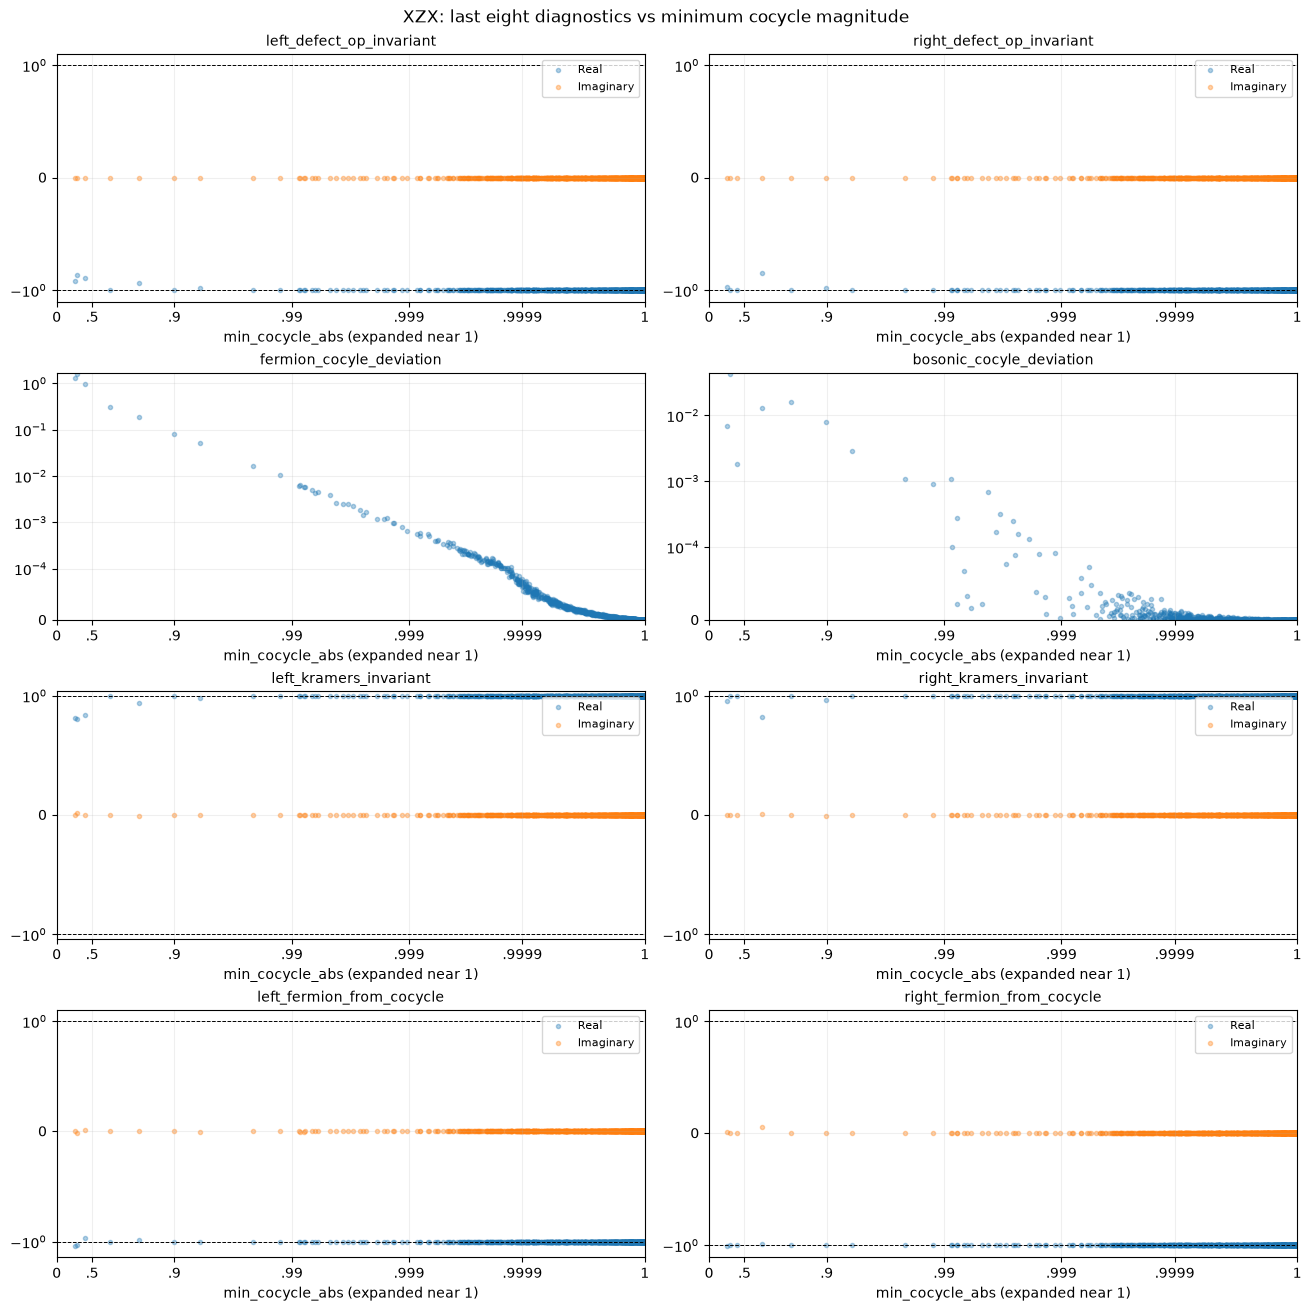

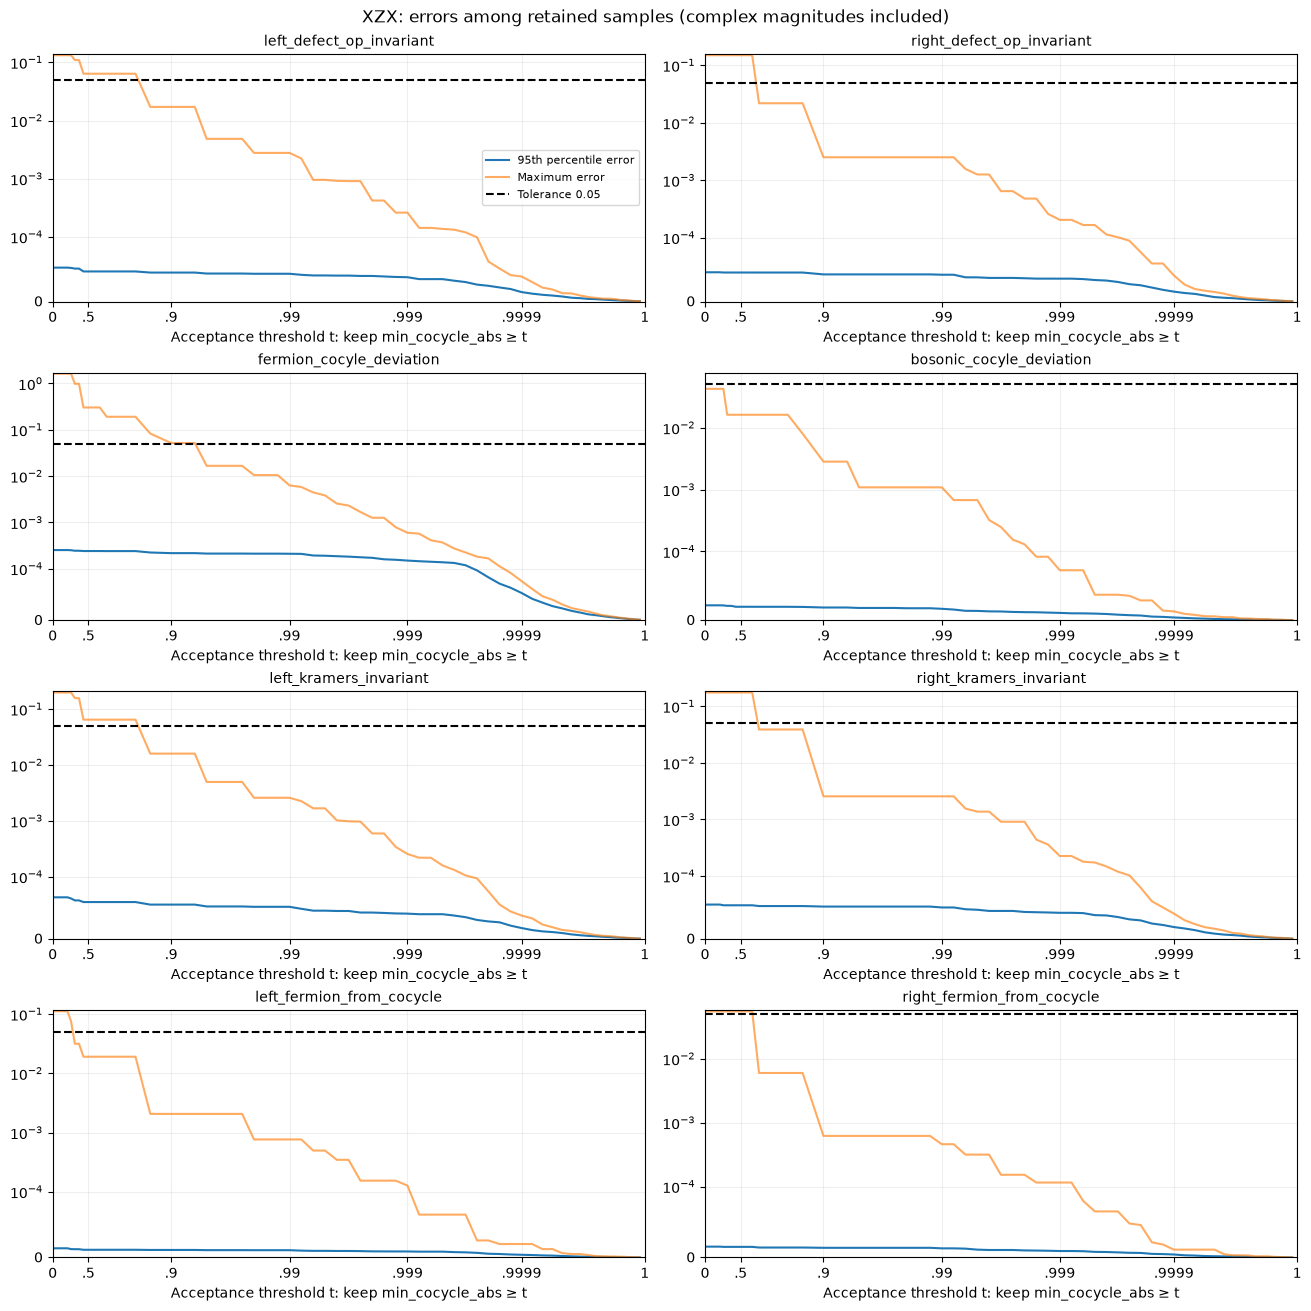

XZX: tolerance=0.05; require 95% of retained samples to pass all eight; at least 50 samples.
First qualifying tested threshold: 0.000000; retains 1000/1000 samples. This is an empirical candidate, not a validated universal cutoff.
Default invariant errors measure distance to either ±1, not correctness of the SPT class. Supply targets={column: expected_sign} to test a known class.


,threshold,retained_n,retained_fraction,all_eight_pass_fraction,q95_max_error_across_eight,max_error_across_eight
0,0.000000,1000,1.000,0.993,2.526390e-04,1.629646e+00
1,0.050000,1000,1.000,0.993,2.526390e-04,1.629646e+00
2,0.100000,1000,1.000,0.993,2.526390e-04,1.629646e+00
3,0.150000,1000,1.000,0.993,2.526390e-04,1.629646e+00
4,0.200000,1000,1.000,0.993,2.526390e-04,1.629646e+00
...,...,...,...,...,...,...
64,0.999997,210,0.210,1.000,1.690490e-06,2.320641e-06
65,0.999998,182,0.182,1.000,1.227343e-06,1.655760e-06
66,0.999998,159,0.159,1.000,1.003115e-06,1.194069e-06
67,0.999999,142,0.142,1.000,8.437900e-07,9.230011e-07


In [95]:
xzx_threshold_report = plot_diagnostic_dependence(
    xzx_diagnostics, "XZX", tolerance=0.05,
    required_pass_fraction=0.95, min_samples=50,
)
xzx_threshold_report

### Analyze results

#### Projector scores

In [96]:
np.round(np.array([
    d['left_proj_vec_results'][0][-1]
    for d in xzx_results
]), 3)

array([-0.   ,  0.   , -0.   , -0.   ,  0.   , -0.   , -0.   , -0.   ,
       -0.   ,  0.   , -0.   ,  0.   , -0.   , -0.   , -0.   , -0.   ,
       -0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,  0.   , -0.   ,
        0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,  0.   , -0.   ,
       -0.   ,  0.   ,  0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
       -0.   , -0.   , -0.   , -0.   , -0.   ,  0.   , -0.   ,  0.   ,
       -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
       -0.   , -0.   ,  0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
       -0.   , -0.   , -0.   ,  0.   , -0.   ,  0.   ,  0.   , -0.   ,
       -0.   , -0.   ,  0.   ,  0.   , -0.   ,  0.   , -0.   , -0.   ,
       -0.   ,  0.   , -0.   , -0.   , -0.   , -0.   ,  0.   , -0.   ,
        0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
       -0.   , -0.   , -0.   , -0.   ,  0.   , -0.   , -0.   , -0.   ,
       -0.   , -0.   , -0.   ,  0.   , -0.   , -0.   ,  0.   , -0.   ,
      

In [97]:
np.round(np.array([
    d['right_proj_vec_results'][0][-1]
    for d in xzx_results
]), 3)

array([ 0., -0., -0., -0., -0., -0.,  0.,  0., -0., -0., -0., -0.,  0.,
        0., -0., -0., -0.,  0., -0., -0., -0., -0.,  0., -0., -0.,  0.,
       -0., -0., -0.,  0.,  0.,  0.,  0.,  0., -0., -0., -0., -0., -0.,
        0.,  0.,  0., -0., -0.,  0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0.,  0., -0., -0.,  0., -0., -0., -0., -0.,  0., -0., -0.,
        0.,  0.,  0., -0., -0., -0., -0., -0.,  0., -0., -0.,  0.,  0.,
       -0.,  0., -0., -0., -0., -0.,  0., -0., -0., -0.,  0.,  0., -0.,
       -0., -0.,  0., -0., -0.,  0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0.,  0., -0., -0., -0.,  0., -0.,  0., -0., -0.,  0.,
       -0., -0.,  0., -0., -0., -0., -0.,  0., -0.,  0., -0.,  0., -0.,
       -0., -0.,  0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0.,  0.,  0.,  0., -0., -0., -0., -0.,  0.,  0., -0.,
       -0., -0.,  0., -0., -0.,  0., -0., -0.,  0.,  0., -0., -0., -0.,
       -0., -0.,  0., -0., -0., -0., -0., -0.,  0., -0., -0., -0

In [98]:
def get_schmidt_vals_ratio(schmidt_vals):
    if len(schmidt_vals.data) > 1:
        return schmidt_vals.data[1]/schmidt_vals.data[0]
    else:
        return 0

In [99]:
np.round(np.array([
    get_schmidt_vals_ratio(d['left_proj_vec_results'][1])
    for d in xzx_results
]), 3)

array([0.001, 0.004, 0.002, 0.003, 0.006, 0.   , 0.002, 0.   , 0.   ,
       0.012, 0.001, 0.003, 0.   , 0.   , 0.002, 0.001, 0.001, 0.002,
       0.001, 0.001, 0.   , 0.001, 0.005, 0.   , 0.008, 0.001, 0.   ,
       0.   , 0.   , 0.002, 0.004, 0.001, 0.001, 0.   , 0.005, 0.   ,
       0.   , 0.   , 0.002, 0.002, 0.003, 0.   , 0.001, 0.001, 0.002,
       0.005, 0.001, 0.003, 0.003, 0.   , 0.   , 0.001, 0.001, 0.001,
       0.001, 0.   , 0.002, 0.005, 0.004, 0.   , 0.002, 0.001, 0.002,
       0.001, 0.001, 0.   , 0.002, 0.001, 0.   , 0.008, 0.003, 0.002,
       0.   , 0.002, 0.005, 0.005, 0.001, 0.004, 0.002, 0.   , 0.002,
       0.004, 0.001, 0.001, 0.   , 0.002, 0.   , 0.002, 0.004, 0.002,
       0.002, 0.001, 0.001, 0.   , 0.002, 0.   , 0.   , 0.001, 0.   ,
       0.003, 0.007, 0.001, 0.   , 0.   , 0.   , 0.005, 0.001, 0.   ,
       0.   , 0.001, 0.004, 0.   , 0.001, 0.001, 0.   , 0.003, 0.001,
       0.002, 0.001, 0.003, 0.001, 0.007, 0.002, 0.001, 0.   , 0.002,
       0.003, 0.002,

In [100]:
np.round(np.array([
    get_schmidt_vals_ratio(d['right_proj_vec_results'][1])
    for d in xzx_results
]), 3)

array([0.009, 0.   , 0.001, 0.001, 0.   , 0.   , 0.004, 0.002, 0.001,
       0.001, 0.   , 0.001, 0.007, 0.   , 0.   , 0.   , 0.   , 0.004,
       0.   , 0.001, 0.   , 0.   , 0.015, 0.   , 0.   , 0.002, 0.002,
       0.001, 0.   , 0.008, 0.004, 0.009, 0.002, 0.004, 0.001, 0.   ,
       0.001, 0.001, 0.   , 0.004, 0.004, 0.006, 0.   , 0.   , 0.005,
       0.001, 0.001, 0.001, 0.002, 0.001, 0.002, 0.002, 0.003, 0.002,
       0.004, 0.002, 0.001, 0.   , 0.003, 0.   , 0.001, 0.002, 0.003,
       0.   , 0.002, 0.004, 0.001, 0.003, 0.   , 0.001, 0.002, 0.001,
       0.001, 0.005, 0.002, 0.001, 0.005, 0.01 , 0.001, 0.003, 0.001,
       0.002, 0.001, 0.001, 0.005, 0.002, 0.001, 0.001, 0.004, 0.003,
       0.001, 0.   , 0.001, 0.002, 0.002, 0.001, 0.   , 0.002, 0.001,
       0.   , 0.001, 0.   , 0.002, 0.001, 0.001, 0.001, 0.001, 0.   ,
       0.001, 0.001, 0.001, 0.   , 0.001, 0.003, 0.001, 0.002, 0.004,
       0.001, 0.003, 0.01 , 0.   , 0.004, 0.001, 0.   , 0.   , 0.   ,
       0.008, 0.   ,

#### Purities

In [101]:
np.round(np.array(
    [d['cut_rho_purity'] for d in xzx_results]
), 3)

array([0.994+0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 0.999-0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 0.987+0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 0.999+0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 

In [102]:
np.round(np.array(
    [d['sub_cut_rho_trace'] for d in xzx_results]
), 3)

array([1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j,
      

In [103]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in xzx_results]
), 3)

array([0.994+0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 0.999+0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 0.987-0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 0.999+0.j,
       1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 

Purities are the same, which one could likely prove.

In [104]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in xzx_results]
), 3)

array([0.994+0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 0.999+0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 0.987-0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 0.999+0.j,
       1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 

#### Cut state results

In [105]:
np.array(
    [d['cut_state_fermion_parity'] for d in xzx_results]
)

array([ 1.        -4.63557349e-19j,  1.        +2.41592582e-19j,
        1.        -1.33820653e-19j,  1.        +2.42500043e-20j,
        1.        -2.71846504e-19j,  1.        -3.08329247e-20j,
       -1.        -2.18479640e-19j, -1.        -5.75165958e-21j,
       -1.        -9.63527720e-20j, -1.        +4.22099702e-20j,
        1.        -7.59230987e-20j, -1.        -1.84279717e-19j,
        1.        +4.27373451e-21j, -1.        -5.24367927e-20j,
        1.        -1.90367091e-19j, -1.        -2.12447437e-19j,
       -1.        -1.54334197e-21j,  1.        +1.18230723e-19j,
       -1.        -1.86748450e-19j, -1.        +1.78632779e-19j,
        1.        -2.29962258e-20j, -1.        +1.78597453e-19j,
        1.        +1.43010662e-19j, -1.        +1.59403368e-19j,
       -1.        +2.45489847e-19j,  1.        -1.52626192e-19j,
       -1.        +1.26356092e-19j,  1.        -1.30732823e-19j,
        1.        +4.77284212e-19j,  1.        -3.94613927e-21j,
       -1.        -5.7354

So the FP of the cut state can be even or odd. Interesting!

In [106]:
np.round(np.array(
    [d['cut_overlap'] for d in xzx_results]
), 3)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1.

#### Defect op scores overlaps

In [107]:
np.round(np.array([
    [d['defect_ops_scores'][i][-1] for d in xzx_results]
    for i in range(3)
]), 5)

array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.]], shape=(3, 1000))

#### Phases

In [108]:
xzx_left_phases = np.array([
    d['left_defect_op_invariant'] for d in xzx_results
])

In [109]:
xzx_left_phases.shape

(1000,)

In [110]:
np.round(xzx_left_phases, 3)

array([-0.998+0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j, -1.   -0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   +0.j, -1.   +0.j, -1.   +0.j, -1.   +0.j, -1.   -

In [111]:
xzx_right_phases = np.array([
    d['right_defect_op_invariant'] for d in xzx_results
])

In [112]:
xzx_right_phases.shape

(1000,)

In [113]:
np.round(xzx_right_phases, 3)

array([-1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   +0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j,
       -1.   -0.j, -1.   -0.j, -0.998-0.j, -1.   -0.j, -1.   -0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   -0.j,
       -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j,
       -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j,
       -1.   +0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   +0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j,
       -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -

In [114]:
xzx_X = np.stack([xzx_left_phases, xzx_right_phases], axis=1)

In [115]:
np.max(np.abs(np.imag(xzx_X)))

np.float64(2.0097826830522768e-16)

#### Cocyle information

In [116]:
xzx_cocycle_equation_array = np.array([d['cocycle_equation_output'] for d in xzx_results])
print(np.linalg.norm(xzx_cocycle_equation_array-1))
print(np.max(np.abs(xzx_cocycle_equation_array-1)))

5.467226264622113
1.6296463205933538


Very large errors...! What's going on?

In [117]:
xzx_bosonic_cocycle_equation_array = np.array([d['bosonic_cocycle_equation_output'] for d in xzx_results])

In [118]:
xzx_bosonic_cocycle_equation_array.shape

(1000, 2, 2, 2, 2)

In [119]:
np.linalg.norm(xzx_bosonic_cocycle_equation_array-1)

np.float64(0.04863911733066167)

In [120]:
xzx_X = np.array([d['cocycles'][:, 0,1,0,1] for d in xzx_results])

In [121]:
np.round(xzx_X, 3)

array([[0.998+0.j, 1.   -0.j],
       [1.   -0.j, 1.   -0.j],
       [1.   +0.j, 1.   +0.j],
       ...,
       [1.   -0.j, 1.   -0.j],
       [1.   +0.j, 1.   +0.j],
       [1.   +0.j, 1.   +0.j]], shape=(1000, 2))

In [122]:
np.max(np.abs(np.imag(xzx_X)))

np.float64(0.017037701482667568)

In [123]:
xzx_X=np.array([d['fermion_decoration_from_cocycle'] for d in xzx_results])

In [124]:
np.round(xzx_X, 3)

array([[-1.+0.j, -1.-0.j],
       [-1.-0.j, -1.+0.j],
       [-1.+0.j, -1.+0.j],
       ...,
       [-1.+0.j, -1.-0.j],
       [-1.+0.j, -1.-0.j],
       [-1.-0.j, -1.+0.j]], shape=(1000, 2))

In [125]:
np.max(np.abs(np.imag(xzx_X)))

np.float64(0.05349791616512785)

In [126]:
cocycles = np.asarray([d['cocycles'] for d in xzx_results])

In [127]:
min_abs_cocycle = np.abs(cocycles).reshape(len(xzx_results), -1).min(axis=1)

In [128]:
min_abs_cocycle.shape

(1000,)

In [129]:
np.sort(min_abs_cocycle)[:150]

array([0.29805276, 0.33223386, 0.42071278, 0.64694676, 0.80063478,
       0.89859528, 0.93965007, 0.97849664, 0.98747466, 0.99127364,
       0.99148289, 0.99214482, 0.99222652, 0.99319917, 0.99357813,
       0.9940299 , 0.99525088, 0.99577008, 0.99634004, 0.99666245,
       0.99700056, 0.9973793 , 0.99752688, 0.99765418, 0.9981108 ,
       0.99834985, 0.99845035, 0.9986184 , 0.99864137, 0.99885991,
       0.99896772, 0.99914163, 0.99919407, 0.9991997 , 0.99931569,
       0.99932377, 0.99940097, 0.99942607, 0.99943897, 0.99949467,
       0.99953282, 0.99953615, 0.99954946, 0.99955347, 0.9995819 ,
       0.99958583, 0.99961396, 0.9996271 , 0.9996367 , 0.99963877,
       0.99964911, 0.99965048, 0.99966479, 0.99966616, 0.99966704,
       0.99967682, 0.99968757, 0.99969151, 0.99969348, 0.99969397,
       0.9996965 , 0.99970314, 0.99970938, 0.99971609, 0.99972607,
       0.99972864, 0.99973033, 0.99973556, 0.99974312, 0.99974579,
       0.99974938, 0.99975186, 0.99975442, 0.99975609, 0.99976

In [130]:
xzx_X = np.array([d['cocycles'][:, 0,1,0,1] for d in xzx_results])

In [131]:
xzx_X = np.column_stack([xzx_X, min_abs_cocycle])

In [132]:
xzx_X

array([[0.99774873+1.65431265e-05j, 0.9999339 -3.31652413e-06j,
        0.99357813+0.00000000e+00j],
       [0.99998679-8.85977825e-07j, 0.99999984-2.68136706e-09j,
        0.99996574+0.00000000e+00j],
       [0.99999748+5.95465648e-08j, 0.9999987 +2.76285668e-07j,
        0.99999213+0.00000000e+00j],
       ...,
       [0.99999379-1.43149370e-06j, 0.99999871-3.39322773e-08j,
        0.99997587+0.00000000e+00j],
       [0.99999898+2.86636735e-08j, 0.99999959+1.36751415e-08j,
        0.99999664+0.00000000e+00j],
       [0.99999939+7.91218327e-08j, 0.99999995+2.98368101e-09j,
        0.99999817+0.00000000e+00j]], shape=(1000, 3))

In [133]:
xzx_X = xzx_X[np.abs(xzx_X[:, 2]).argsort()]

In [134]:
np.round(xzx_X[:10], 3)

array([[0.818-0.j   , 0.955-0.003j, 0.298+0.j   ],
       [0.802+0.017j, 1.   -0.j   , 0.332+0.j   ],
       [0.843-0.001j, 1.   -0.j   , 0.421+0.j   ],
       [1.   +0.j   , 0.825+0.005j, 0.647+0.j   ],
       [0.936-0.008j, 1.   -0.j   , 0.801+0.j   ],
       [1.   -0.j   , 0.961-0.004j, 0.899+0.j   ],
       [0.984+0.001j, 1.   -0.j   , 0.94 +0.j   ],
       [0.995+0.001j, 1.   -0.j   , 0.978+0.j   ],
       [1.   -0.j   , 0.998+0.j   , 0.987+0.j   ],
       [0.997-0.001j, 1.   +0.j   , 0.991+0.j   ]])

In [135]:
np.round(xzx_X[-10:], 3)

array([[1.+0.j, 1.-0.j, 1.+0.j],
       [1.-0.j, 1.-0.j, 1.+0.j],
       [1.-0.j, 1.-0.j, 1.+0.j],
       [1.+0.j, 1.+0.j, 1.+0.j],
       [1.-0.j, 1.-0.j, 1.+0.j],
       [1.-0.j, 1.-0.j, 1.+0.j],
       [1.-0.j, 1.+0.j, 1.+0.j],
       [1.+0.j, 1.-0.j, 1.+0.j],
       [1.+0.j, 1.-0.j, 1.+0.j],
       [1.+0.j, 1.-0.j, 1.+0.j]])

## YZY state

In [136]:
with open("results/z_2_t_yzy_results.pkl", "rb") as file:
    yzy_results = pickle.load(file)

In [137]:
yzy_diagnostics = summarize_saved_results(yzy_results)

In [138]:
yzy_diagnostics

,min_cocycle_abs,min_defect_overlap,cut_purity,sub_cut_purity,left_defect_op_invariant,right_defect_op_invariant,fermion_cocyle_deviation,bosonic_cocyle_deviation,left_kramers_invariant,right_kramers_invariant,left_fermion_from_cocycle,right_fermion_from_cocycle
sample,,,,,,,,,,,,
965,0.286550,1.0,0.501715,0.501715,-0.999999-0.000000j,-0.608022-0.000000j,2.001811e+00,2.737979e-02,-0.999999+0.000000j,-0.708190+0.009696j,-1.000000-0.000000j,-0.823697+0.018680j
502,0.318004,1.0,0.508299,0.508299,-1.000000-0.000000j,-0.704524-0.000000j,1.379376e+00,5.548874e-02,-0.999999-0.000000j,-0.696847+0.019341j,-1.000000-0.000000j,-1.038252+0.076294j
646,0.323941,1.0,0.510411,0.510411,-1.000000+0.000000j,-0.849463+0.000000j,1.393902e+00,3.110787e-02,-1.000000-0.000000j,-0.764350-0.011890j,-1.000000+0.000000j,-0.981538+0.104007j
126,0.576586,1.0,0.656296,0.656296,-0.906492+0.000000j,-0.999996+0.000000j,5.029084e-01,3.964610e-02,-0.865701-0.017164j,-0.999996-0.000000j,-1.000347-0.037655j,-1.000000+0.000000j
409,0.590268,1.0,0.655584,0.655584,-0.892990+0.000000j,-1.000000-0.000000j,5.065211e-01,5.349834e-02,-0.788765+0.021106j,-1.000000-0.000000j,-0.958522+0.042162j,-1.000000-0.000000j
...,...,...,...,...,...,...,...,...,...,...,...,...
710,1.000000,1.0,1.000000,1.000000,-1.000000-0.000000j,-1.000000-0.000000j,5.216610e-09,5.050567e-11,-1.000000-0.000000j,-1.000000-0.000000j,-1.000000+0.000000j,-1.000000+0.000000j
562,1.000000,1.0,1.000000,1.000000,-1.000000-0.000000j,-1.000000-0.000000j,5.507694e-09,7.501119e-11,-1.000000+0.000000j,-1.000000-0.000000j,-1.000000+0.000000j,-1.000000+0.000000j
681,1.000000,1.0,1.000000,1.000000,-1.000000+0.000000j,-1.000000-0.000000j,5.266043e-09,5.763104e-10,-1.000000-0.000000j,-1.000000+0.000000j,-1.000000-0.000000j,-1.000000-0.000000j


In [139]:
X = yzy_diagnostics.iloc[:, -8:].to_numpy()

In [140]:
np.max(np.abs(np.imag(X)), axis=0)

array([1.64835642e-16, 1.40025706e-16, 0.00000000e+00, 0.00000000e+00,
       2.11063624e-02, 1.93410242e-02, 4.21618577e-02, 1.04006971e-01])

In [141]:
sub_yzy_diagnostics = yzy_diagnostics[yzy_diagnostics['min_cocycle_abs'] >= 0.975]

In [142]:
len(sub_yzy_diagnostics)

988

In [143]:
X = sub_yzy_diagnostics.iloc[:, -8:].to_numpy()

In [144]:
np.max(np.abs(np.imag(X)), axis=0)

array([1.64835642e-16, 1.40025706e-16, 0.00000000e+00, 0.00000000e+00,
       2.45417459e-04, 2.44703432e-04, 6.75474564e-04, 1.10214735e-03])

In [216]:
yzy_diagnostics['sub_cut_purity'].min()

np.float64(0.5017150715880945)

In [217]:
sub_yzy_diagnostics['sub_cut_purity'].min()

np.float64(0.9931730040609704)

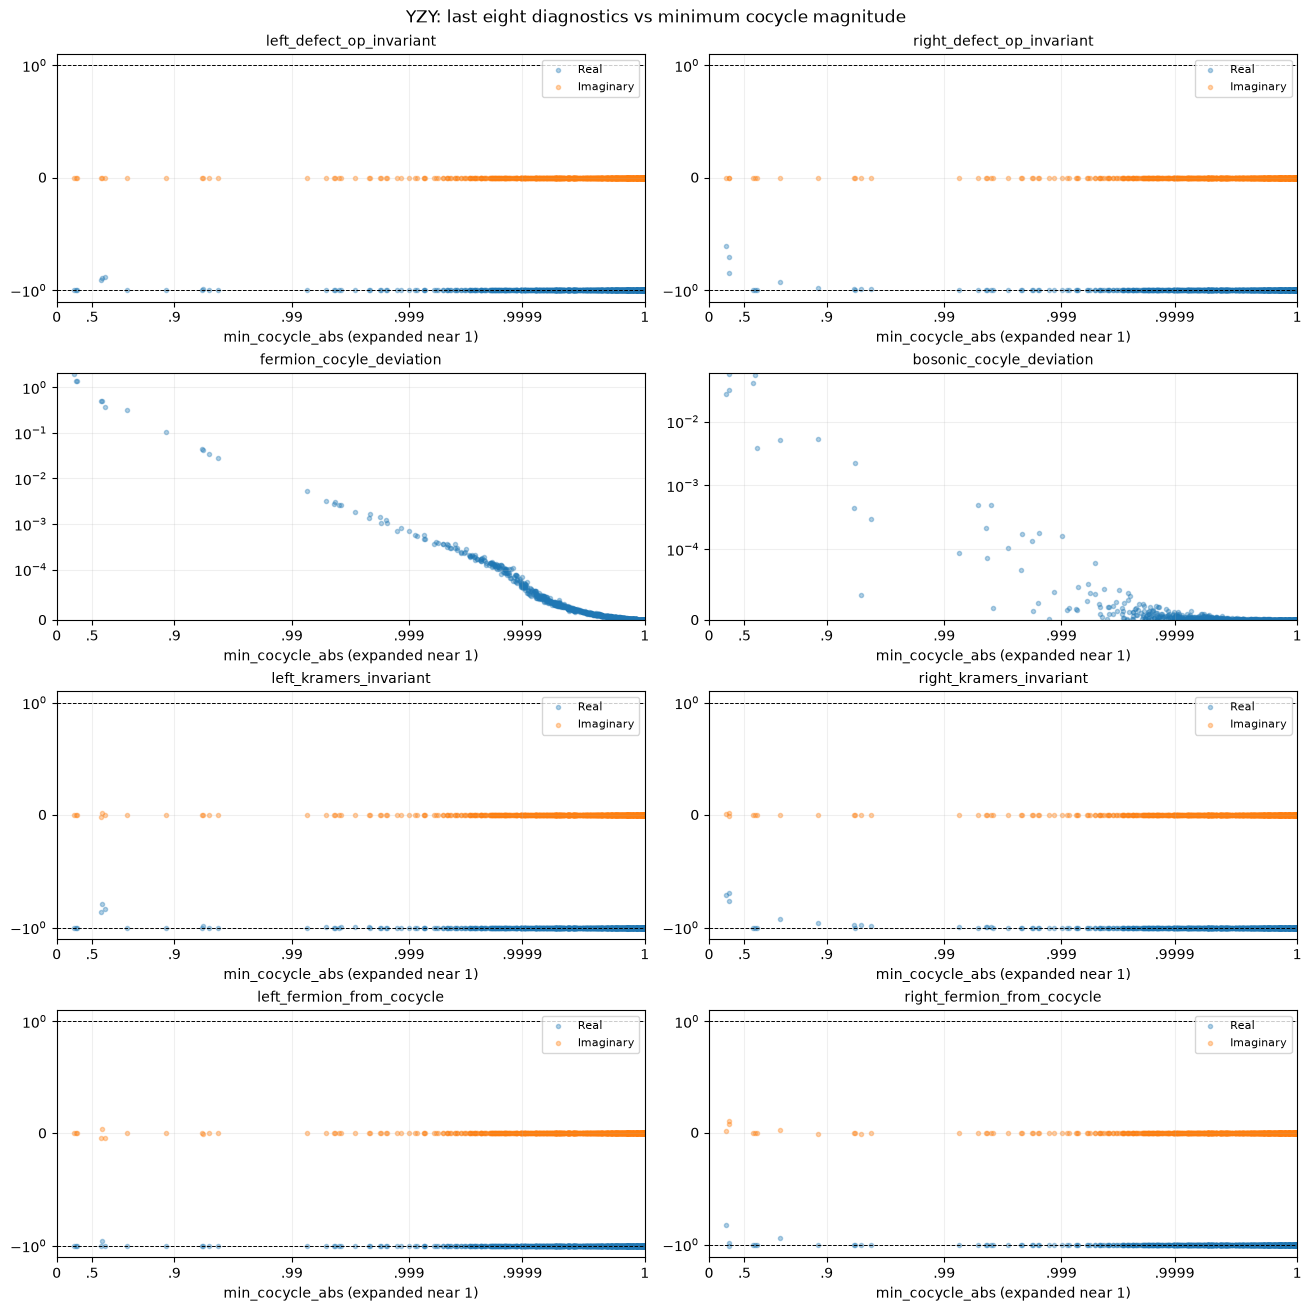

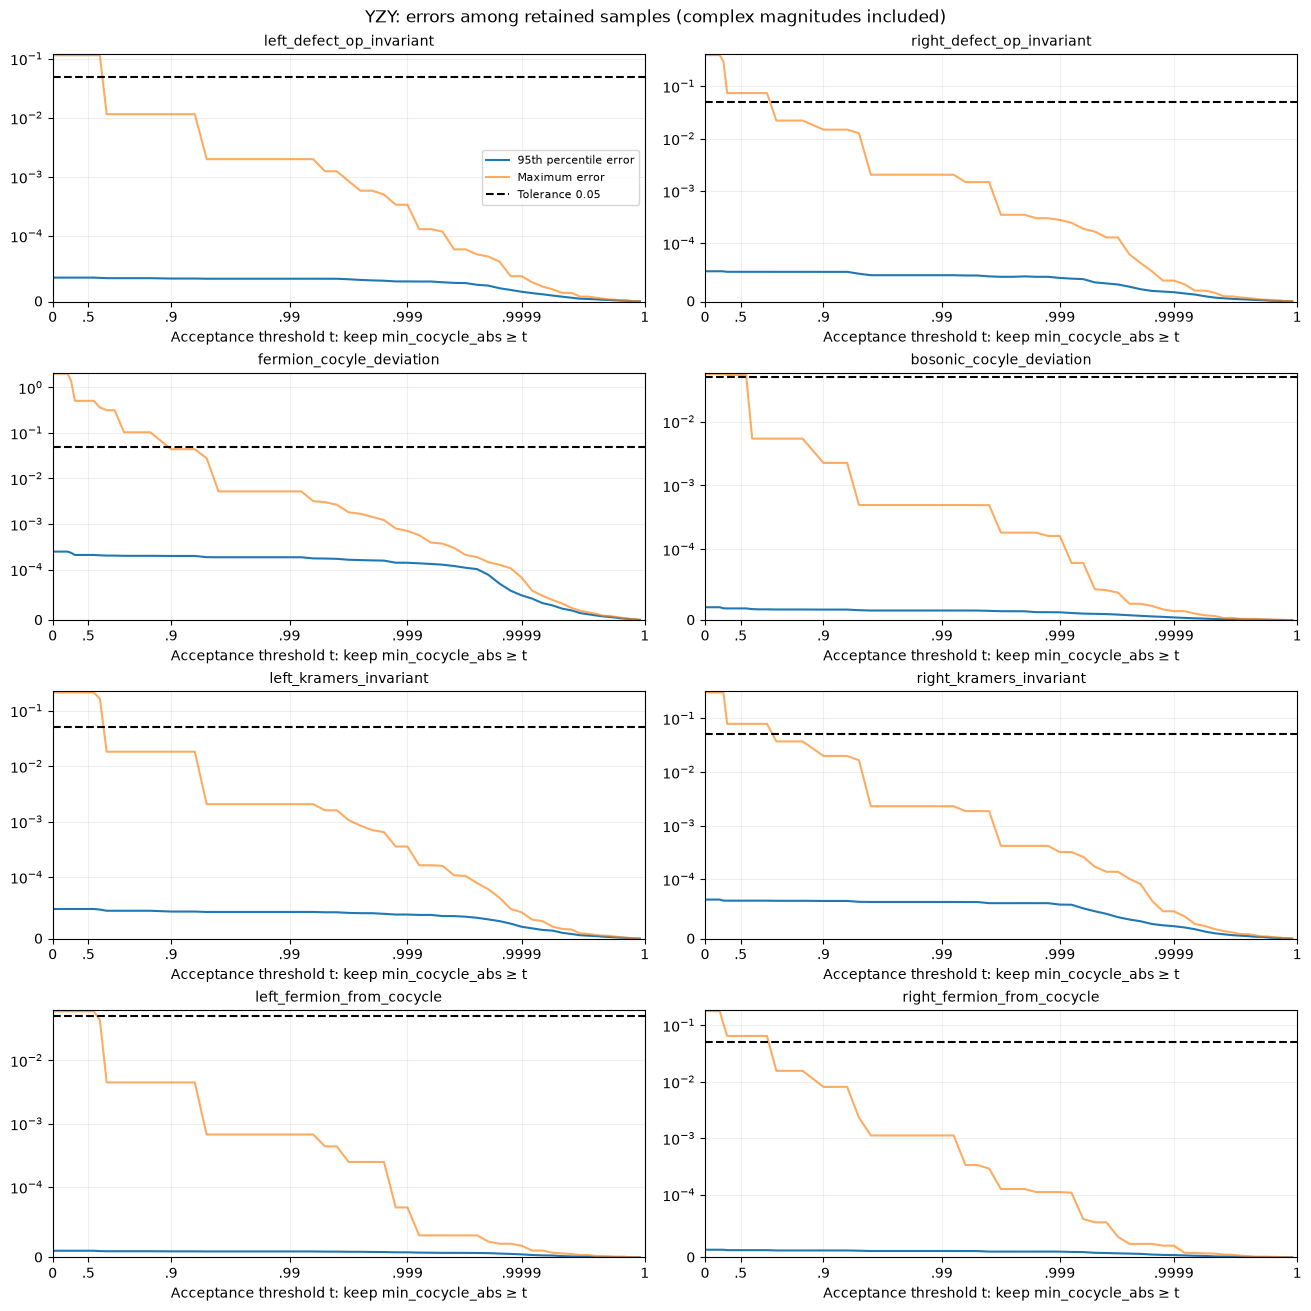

YZY: tolerance=0.05; require 95% of retained samples to pass all eight; at least 50 samples.
First qualifying tested threshold: 0.000000; retains 1000/1000 samples. This is an empirical candidate, not a validated universal cutoff.
Default invariant errors measure distance to either ±1, not correctness of the SPT class. Supply targets={column: expected_sign} to test a known class.


,threshold,retained_n,retained_fraction,all_eight_pass_fraction,q95_max_error_across_eight,max_error_across_eight
0,0.000000,1000,1.000,0.992,2.478207e-04,2.001811e+00
1,0.050000,1000,1.000,0.992,2.478207e-04,2.001811e+00
2,0.100000,1000,1.000,0.992,2.478207e-04,2.001811e+00
3,0.150000,1000,1.000,0.992,2.478207e-04,2.001811e+00
4,0.200000,1000,1.000,0.992,2.478207e-04,2.001811e+00
...,...,...,...,...,...,...
64,0.999997,201,0.201,1.000,1.585367e-06,2.090829e-06
65,0.999998,184,0.184,1.000,1.364727e-06,1.534405e-06
66,0.999998,147,0.147,1.000,1.054559e-06,1.275029e-06
67,0.999999,127,0.127,1.000,7.575592e-07,8.412250e-07


In [145]:
yzy_threshold_report = plot_diagnostic_dependence(
    yzy_diagnostics, "YZY", tolerance=0.05,
    required_pass_fraction=0.95, min_samples=50,
)
yzy_threshold_report

### Analyze results

#### Projector scores

In [146]:
np.round(np.array([
    d['left_proj_vec_results'][0][-1]
    for d in yzy_results
]), 3)

array([-0., -0., -0.,  0., -0.,  0., -0.,  0., -0.,  0., -0., -0.,  0.,
       -0., -0.,  0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
        0., -0., -0., -0.,  0., -0., -0.,  0., -0., -0., -0., -0., -0.,
       -0.,  0., -0., -0.,  0., -0., -0.,  0., -0.,  0., -0., -0.,  0.,
       -0., -0., -0., -0.,  0.,  0., -0., -0., -0.,  0., -0., -0., -0.,
        0.,  0.,  0.,  0.,  0., -0.,  0., -0.,  0., -0., -0., -0., -0.,
       -0., -0.,  0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0., -0., -0., -0., -0.,  0., -0., -0., -0., -0., -0.,
       -0., -0., -0., -0., -0., -0.,  0., -0., -0., -0.,  0., -0., -0.,
       -0., -0.,  0., -0., -0., -0., -0., -0., -0.,  0., -0.,  0., -0.,
       -0., -0., -0.,  0., -0., -0., -0., -0., -0., -0.,  0., -0., -0.,
       -0., -0.,  0., -0., -0.,  0., -0., -0.,  0.,  0., -0., -0., -0.,
       -0., -0., -0.,  0., -0., -0., -0., -0.,  0., -0.,  0., -0., -0.,
        0., -0., -0.,  0., -0., -0.,  0., -0.,  0., -0., -0., -0

In [147]:
np.round(np.array([
    d['right_proj_vec_results'][0][-1]
    for d in yzy_results
]), 3)

array([-0.   , -0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   , -0.   ,
        0.   , -0.   , -0.   ,  0.   ,  0.   , -0.   ,  0.   , -0.   ,
       -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
        0.   , -0.   ,  0.   ,  0.   ,  0.   , -0.   , -0.   ,  0.   ,
       -0.   , -0.   , -0.   , -0.   ,  0.   , -0.   , -0.   ,  0.   ,
       -0.   , -0.   , -0.   ,  0.   , -0.   , -0.   , -0.   ,  0.   ,
       -0.   , -0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   , -0.   ,
       -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
       -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
       -0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   , -0.   , -0.   ,
        0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
        0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   ,
       -0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   ,
       -0.   ,  0.   , -0.   , -0.   ,  0.   , -0.   , -0.   , -0.   ,
      

In [148]:
def get_schmidt_vals_ratio(schmidt_vals):
    if len(schmidt_vals.data) > 1:
        return schmidt_vals.data[1]/schmidt_vals.data[0]
    else:
        return 0

In [149]:
np.round(np.array([
    get_schmidt_vals_ratio(d['left_proj_vec_results'][1])
    for d in yzy_results
]), 3)

array([0.001, 0.   , 0.001, 0.004, 0.001, 0.001, 0.001, 0.   , 0.   ,
       0.007, 0.   , 0.001, 0.006, 0.   , 0.001, 0.003, 0.   , 0.001,
       0.   , 0.   , 0.002, 0.   , 0.001, 0.004, 0.001, 0.002, 0.002,
       0.001, 0.   , 0.   , 0.006, 0.   , 0.001, 0.002, 0.   , 0.004,
       0.002, 0.   , 0.002, 0.002, 0.003, 0.   , 0.003, 0.003, 0.   ,
       0.   , 0.   , 0.   , 0.005, 0.001, 0.001, 0.005, 0.003, 0.   ,
       0.001, 0.001, 0.004, 0.001, 0.001, 0.001, 0.   , 0.004, 0.   ,
       0.   , 0.002, 0.002, 0.004, 0.003, 0.001, 0.007, 0.   , 0.003,
       0.001, 0.002, 0.001, 0.002, 0.001, 0.001, 0.001, 0.   , 0.003,
       0.   , 0.001, 0.   , 0.   , 0.   , 0.001, 0.001, 0.   , 0.001,
       0.001, 0.001, 0.   , 0.001, 0.001, 0.   , 0.001, 0.001, 0.003,
       0.003, 0.001, 0.   , 0.   , 0.001, 0.001, 0.003, 0.   , 0.001,
       0.   , 0.002, 0.   , 0.   , 0.002, 0.002, 0.004, 0.002, 0.001,
       0.001, 0.001, 0.004, 0.   , 0.001, 0.001, 0.   , 0.001, 0.   ,
       0.019, 0.001,

In [150]:
np.round(np.array([
    get_schmidt_vals_ratio(d['right_proj_vec_results'][1])
    for d in yzy_results
]), 3)

array([0.001, 0.002, 0.001, 0.001, 0.001, 0.005, 0.   , 0.001, 0.007,
       0.001, 0.001, 0.002, 0.005, 0.002, 0.002, 0.   , 0.   , 0.   ,
       0.002, 0.001, 0.   , 0.   , 0.001, 0.002, 0.002, 0.002, 0.005,
       0.003, 0.   , 0.001, 0.   , 0.002, 0.001, 0.   , 0.001, 0.001,
       0.008, 0.002, 0.003, 0.003, 0.001, 0.002, 0.001, 0.   , 0.002,
       0.002, 0.   , 0.003, 0.001, 0.   , 0.   , 0.003, 0.   , 0.001,
       0.001, 0.001, 0.003, 0.001, 0.001, 0.   , 0.002, 0.   , 0.   ,
       0.001, 0.002, 0.   , 0.   , 0.001, 0.001, 0.003, 0.001, 0.001,
       0.001, 0.001, 0.006, 0.   , 0.006, 0.002, 0.001, 0.002, 0.003,
       0.   , 0.002, 0.001, 0.001, 0.   , 0.   , 0.002, 0.005, 0.002,
       0.002, 0.001, 0.002, 0.   , 0.002, 0.   , 0.001, 0.002, 0.001,
       0.001, 0.006, 0.002, 0.007, 0.001, 0.002, 0.004, 0.   , 0.001,
       0.005, 0.001, 0.   , 0.   , 0.001, 0.001, 0.   , 0.004, 0.002,
       0.005, 0.001, 0.001, 0.004, 0.004, 0.   , 0.   , 0.001, 0.   ,
       0.002, 0.   ,

#### Purities

In [151]:
np.round(np.array(
    [d['cut_rho_purity'] for d in yzy_results]
), 3)

array([1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 

In [152]:
np.round(np.array(
    [d['sub_cut_rho_trace'] for d in yzy_results]
), 3)

array([1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
      

In [153]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in yzy_results]
), 3)

array([1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 

Purities are the same, which one could likely prove.

In [154]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in yzy_results]
), 3)

array([1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 

#### Cut state results

In [155]:
np.array(
    [d['cut_state_fermion_parity'] for d in yzy_results]
)

array([ 1.        +2.90910845e-19j, -1.        -8.11338442e-20j,
       -1.        -1.08591818e-19j, -1.        +3.45165083e-20j,
        1.        +5.02865154e-20j,  1.        -8.90788964e-20j,
        1.        +3.57386702e-20j,  1.        -2.29760845e-19j,
       -1.        -1.17486703e-19j,  1.        +2.78864762e-19j,
       -1.        -6.55229212e-20j, -1.        +2.51875062e-19j,
        1.        +8.53625818e-20j, -1.        +2.85380433e-19j,
        1.        +2.05027207e-19j, -1.        +8.15362418e-19j,
       -1.        -1.29810595e-19j,  1.        +4.19792784e-19j,
        1.        -1.55624884e-19j, -1.        -1.96235488e-21j,
       -1.        -1.38210982e-19j, -1.        +7.45809731e-20j,
        1.        +8.86812784e-20j,  1.        +4.45626370e-19j,
        1.        +1.75315208e-19j, -1.        +7.73461463e-20j,
        1.        -7.69377113e-20j, -1.        +1.04738950e-19j,
       -1.        +4.92910282e-21j, -1.        +1.30564465e-19j,
       -1.        +4.9422

So the FP of the cut state can be even or odd. Interesting!

In [156]:
np.round(np.array(
    [d['cut_overlap'] for d in yzy_results]
), 3)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1.

#### Defect op scores overlaps

In [157]:
np.round(np.array([
    [d['defect_ops_scores'][i][-1] for d in yzy_results]
    for i in range(3)
]), 5)

array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.]], shape=(3, 1000))

#### Phases

In [158]:
yzy_left_phases = np.array([
    d['left_defect_op_invariant'] for d in yzy_results
])

In [159]:
yzy_left_phases.shape

(1000,)

In [160]:
np.round(yzy_left_phases, 3)

array([-1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j,
       -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   +0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j,
       -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j,
       -1.   +0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j,
       -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j, -1.   -0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j,
       -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   +

In [161]:
yzy_right_phases = np.array([
    d['right_defect_op_invariant'] for d in yzy_results
])

In [162]:
yzy_right_phases.shape

(1000,)

In [163]:
np.round(yzy_right_phases, 3)

array([-1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j, -1.   +0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j,
       -1.   +0.j, -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j,
       -1.   +0.j, -1.   +0.j, -1.   -0.j, -1.   +0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j, -1.   -0.j,
       -1.   -0.j, -1.   +0.j, -1.   -0.j, -1.   -0.j, -1.   +0.j,
       -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   -0.j, -1.   +

#### Cocyle information

In [164]:
yzy_cocycle_equation_array = np.array([d['cocycle_equation_output'] for d in yzy_results])
print(np.linalg.norm(yzy_cocycle_equation_array-1))
print(np.max(np.abs(yzy_cocycle_equation_array-1)))

6.438672723267391
2.0018111794745432


In [165]:
yzy_bosonic_cocycle_equation_array = np.array([d['bosonic_cocycle_equation_output'] for d in yzy_results])

In [166]:
yzy_bosonic_cocycle_equation_array.shape

(1000, 2, 2, 2, 2)

In [167]:
np.linalg.norm(yzy_bosonic_cocycle_equation_array-1)

np.float64(0.09646875813996665)

In [168]:
yzy_results[0]['cocycles'].shape

(2, 2, 2, 2, 2)

In [169]:
np.round(
    np.array([d['cocycles'][:, 0,1,0,1] for d in yzy_results])
, 3)

array([[-1.+0.j, -1.+0.j],
       [-1.+0.j, -1.+0.j],
       [-1.-0.j, -1.+0.j],
       ...,
       [-1.-0.j, -1.+0.j],
       [-1.-0.j, -1.+0.j],
       [-1.-0.j, -1.+0.j]], shape=(1000, 2))

In [170]:
np.round(
    np.array([d['fermion_decoration_from_cocycle'] for d in yzy_results])
, 3)

array([[-1.+0.j, -1.+0.j],
       [-1.-0.j, -1.-0.j],
       [-1.-0.j, -1.+0.j],
       ...,
       [-1.-0.j, -1.+0.j],
       [-1.-0.j, -1.-0.j],
       [-1.-0.j, -1.-0.j]], shape=(1000, 2))

## XZZZX state

In [171]:
with open("results/z_2_t_xzzzx_results.pkl", "rb") as file:
    xzzzx_results = pickle.load(file)

In [172]:
xzzzx_diagnostics = summarize_saved_results(xzzzx_results)

In [173]:
xzzzx_diagnostics

,min_cocycle_abs,min_defect_overlap,cut_purity,sub_cut_purity,left_defect_op_invariant,right_defect_op_invariant,fermion_cocyle_deviation,bosonic_cocyle_deviation,left_kramers_invariant,right_kramers_invariant,left_fermion_from_cocycle,right_fermion_from_cocycle
sample,,,,,,,,,,,,
589,0.023812,0.069865,0.499333,0.499333,0.921819+0.000000j,0.999980+0.000000j,4.098804e+01,1.818761e-05,-0.999645+0.000009j,-0.999970+0.000000j,0.999896+0.000246j,1.000000+0.000001j
739,0.048381,0.101607,0.497547,0.497547,-0.004828+0.000000j,0.999037+0.000000j,1.954264e+01,8.125064e-04,-0.994350-0.000404j,-0.998651-0.000014j,1.001411+0.003936j,1.000212+0.000115j
513,0.192246,0.999748,0.499470,0.499470,0.999965-0.000000j,0.421241-0.000000j,2.445973e+00,1.481532e-01,-0.999944-0.000008j,-0.584141-0.043390j,0.999995-0.000010j,1.026794+0.103559j
621,0.193808,0.999940,0.500189,0.500189,0.367729+0.000000j,0.999572+0.000000j,1.925376e+00,1.008045e-01,-0.535673+0.027033j,-0.999477+0.000016j,0.986959-0.233596j,0.999984+0.000009j
944,0.239201,0.998929,0.499985,0.499985,0.999999-0.000000j,0.360134-0.000000j,1.599527e+00,2.040686e-01,-0.999999+0.000000j,-0.552597+0.056680j,1.000000-0.000000j,1.064674+0.057570j
...,...,...,...,...,...,...,...,...,...,...,...,...
677,1.000000,0.997414,0.999995,0.999995,1.000000-0.000000j,1.000000-0.000000j,1.939657e-07,7.429138e-09,-1.000000+0.000000j,-1.000000-0.000000j,1.000000-0.000000j,1.000000+0.000000j
753,1.000000,1.000000,1.000000,1.000000,1.000000+0.000000j,1.000000+0.000000j,1.809521e-07,1.303006e-08,-1.000000+0.000000j,-1.000000-0.000000j,1.000000+0.000000j,1.000000-0.000000j
424,1.000000,0.902225,1.000000,1.000000,1.000000+0.000000j,1.000000+0.000000j,1.327135e-07,5.358810e-09,-1.000000-0.000000j,-1.000000-0.000000j,1.000000+0.000000j,1.000000+0.000000j


In [174]:
X = xzzzx_diagnostics.iloc[:, -8:].to_numpy()

In [175]:
np.max(np.abs(np.imag(X)), axis=0)

array([8.41401872e-16, 8.36960243e-16, 0.00000000e+00, 0.00000000e+00,
       3.52184186e-02, 5.66796259e-02, 4.78672848e-01, 1.78310344e-01])

In [176]:
sub_xzzzx_diagnostics = xzzzx_diagnostics[xzzzx_diagnostics['min_cocycle_abs'] >= 0.975]

In [218]:
xzzzx_diagnostics['sub_cut_purity'].min()

np.float64(0.1701979328025945)

In [219]:
sub_xzzzx_diagnostics['sub_cut_purity'].min()

np.float64(0.2515750871630118)

In [177]:
len(sub_xzzzx_diagnostics)

532

In [178]:
X = sub_xzzzx_diagnostics.iloc[:, -8:].to_numpy()

In [179]:
np.max(np.abs(np.imag(X)), axis=0)

array([8.41401872e-16, 7.65972741e-16, 0.00000000e+00, 0.00000000e+00,
       1.60500747e-03, 1.27307110e-03, 2.71930753e-03, 3.21779028e-03])

(array([ 12.,  43.,  34.,  86., 150.,  77.,  73.,  69.,  88., 368.]),
 array([0.17019793, 0.25317811, 0.33615829, 0.41913847, 0.50211865,
        0.58509883, 0.66807901, 0.75105919, 0.83403936, 0.91701954,
        0.99999972]),
 <BarContainer object of 10 artists>)

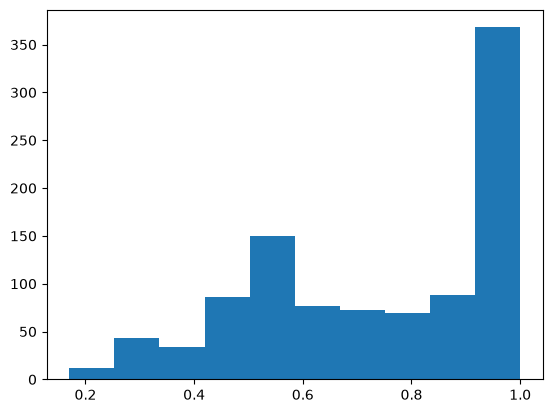

In [210]:
plt.hist(xzzzx_diagnostics['sub_cut_purity'])

(array([  8.,   2.,   5.,  45.,  30.,  25.,  19.,  29.,  29., 340.]),
 array([0.25157509, 0.32641755, 0.40126001, 0.47610248, 0.55094494,
        0.6257874 , 0.70062987, 0.77547233, 0.8503148 , 0.92515726,
        0.99999972]),
 <BarContainer object of 10 artists>)

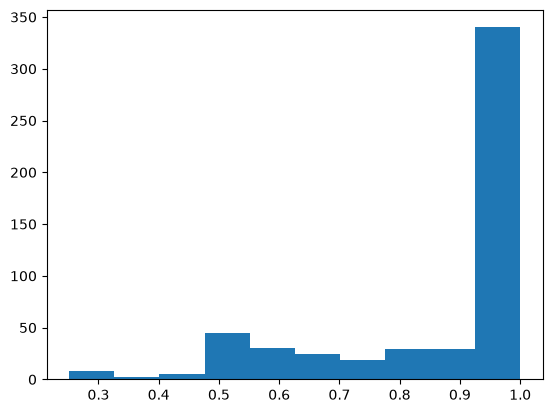

In [211]:
plt.hist(sub_xzzzx_diagnostics['sub_cut_purity'])

### XZZZX cumulative rejection distribution

At threshold $t$, keep samples with `min_cocycle_abs >= t`. The curve shows the fraction strictly below $t$ (discarded); its complement is the retained fraction.


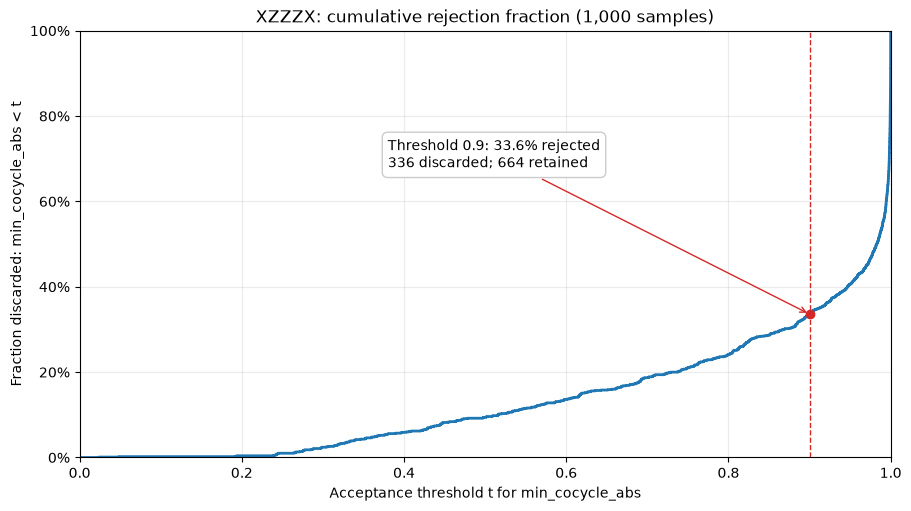

In [180]:
# Rejection CDF for the acceptance rule min_cocycle_abs >= threshold.
from matplotlib.ticker import PercentFormatter

xzzzx_cdf_values = np.sort(xzzzx_diagnostics['min_cocycle_abs'].to_numpy())
assert np.isfinite(xzzzx_cdf_values).all()
xzzzx_cdf_thresholds = np.unique(np.r_[0., xzzzx_cdf_values, 1.])
xzzzx_rejected_fraction = np.searchsorted(
    xzzzx_cdf_values, xzzzx_cdf_thresholds, side='left'
) / len(xzzzx_cdf_values)
xzzzx_rejected_at_09 = np.searchsorted(xzzzx_cdf_values, 0.9, side='left')

fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
# 'pre' gives the strict empirical CDF between successive observed values.
ax.step(xzzzx_cdf_thresholds, xzzzx_rejected_fraction, where='pre',
        color='tab:blue', linewidth=2)
ax.axvline(0.9, color='tab:red', linestyle='--', linewidth=1)
ax.scatter([0.9], [xzzzx_rejected_at_09 / len(xzzzx_cdf_values)],
           color='tab:red', zorder=3)
ax.annotate(
    f'Threshold 0.9: {xzzzx_rejected_at_09 / len(xzzzx_cdf_values):.1%} rejected\n'
    f'{xzzzx_rejected_at_09} discarded; '
    f'{len(xzzzx_cdf_values) - xzzzx_rejected_at_09} retained',
    xy=(0.9, xzzzx_rejected_at_09 / len(xzzzx_cdf_values)),
    xytext=(0.38, 0.68), textcoords='axes fraction',
    arrowprops={'arrowstyle': '->', 'color': 'tab:red'},
    bbox={'facecolor': 'white', 'edgecolor': '0.8', 'boxstyle': 'round,pad=0.4'},
)
ax.set(xlim=(0, max(1., xzzzx_cdf_values[-1])), ylim=(0, 1),
       xlabel='Acceptance threshold t for min_cocycle_abs',
       ylabel='Fraction discarded: min_cocycle_abs < t',
       title=f'XZZZX: cumulative rejection fraction ({len(xzzzx_cdf_values):,} samples)')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(alpha=0.25)
plt.show()


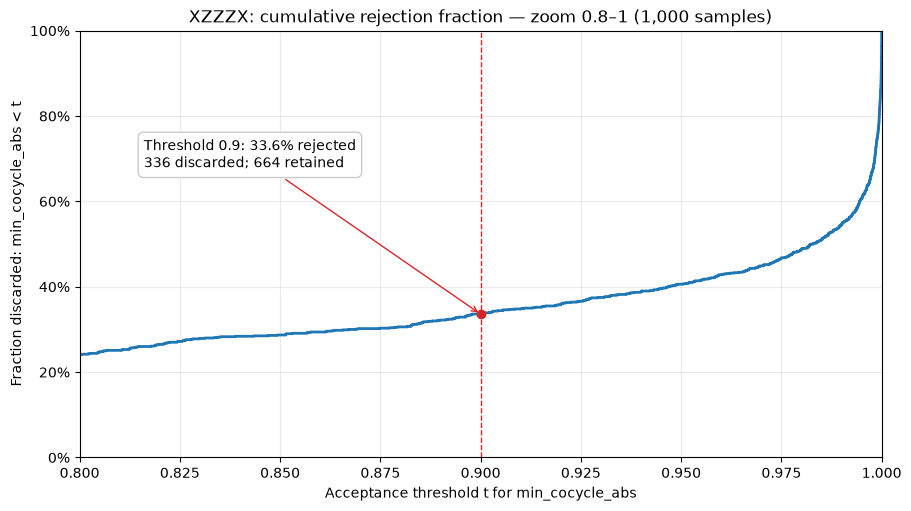

In [181]:
# Zoomed rejection CDF: thresholds 0.8–1.
from matplotlib.ticker import PercentFormatter

xzzzx_cdf_values = np.sort(xzzzx_diagnostics['min_cocycle_abs'].to_numpy())
assert np.isfinite(xzzzx_cdf_values).all()
xzzzx_cdf_thresholds = np.unique(np.r_[0., xzzzx_cdf_values, 1.])
xzzzx_rejected_fraction = np.searchsorted(
    xzzzx_cdf_values, xzzzx_cdf_thresholds, side='left'
) / len(xzzzx_cdf_values)
xzzzx_rejected_at_09 = np.searchsorted(xzzzx_cdf_values, 0.9, side='left')

fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
# 'pre' gives the strict empirical CDF between successive observed values.
ax.step(xzzzx_cdf_thresholds, xzzzx_rejected_fraction, where='pre',
        color='tab:blue', linewidth=2)
ax.axvline(0.9, color='tab:red', linestyle='--', linewidth=1)
ax.scatter([0.9], [xzzzx_rejected_at_09 / len(xzzzx_cdf_values)],
           color='tab:red', zorder=3)
ax.annotate(
    f'Threshold 0.9: {xzzzx_rejected_at_09 / len(xzzzx_cdf_values):.1%} rejected\n'
    f'{xzzzx_rejected_at_09} discarded; '
    f'{len(xzzzx_cdf_values) - xzzzx_rejected_at_09} retained',
    xy=(0.9, xzzzx_rejected_at_09 / len(xzzzx_cdf_values)),
    xytext=(0.08, 0.68), textcoords='axes fraction',
    arrowprops={'arrowstyle': '->', 'color': 'tab:red'},
    bbox={'facecolor': 'white', 'edgecolor': '0.8', 'boxstyle': 'round,pad=0.4'},
)
ax.set(xlim=(0.8, 1.), ylim=(0, 1),
       xlabel='Acceptance threshold t for min_cocycle_abs',
       ylabel='Fraction discarded: min_cocycle_abs < t',
       title=f'XZZZX: cumulative rejection fraction — zoom 0.8–1 ({len(xzzzx_cdf_values):,} samples)')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(alpha=0.25)
plt.show()


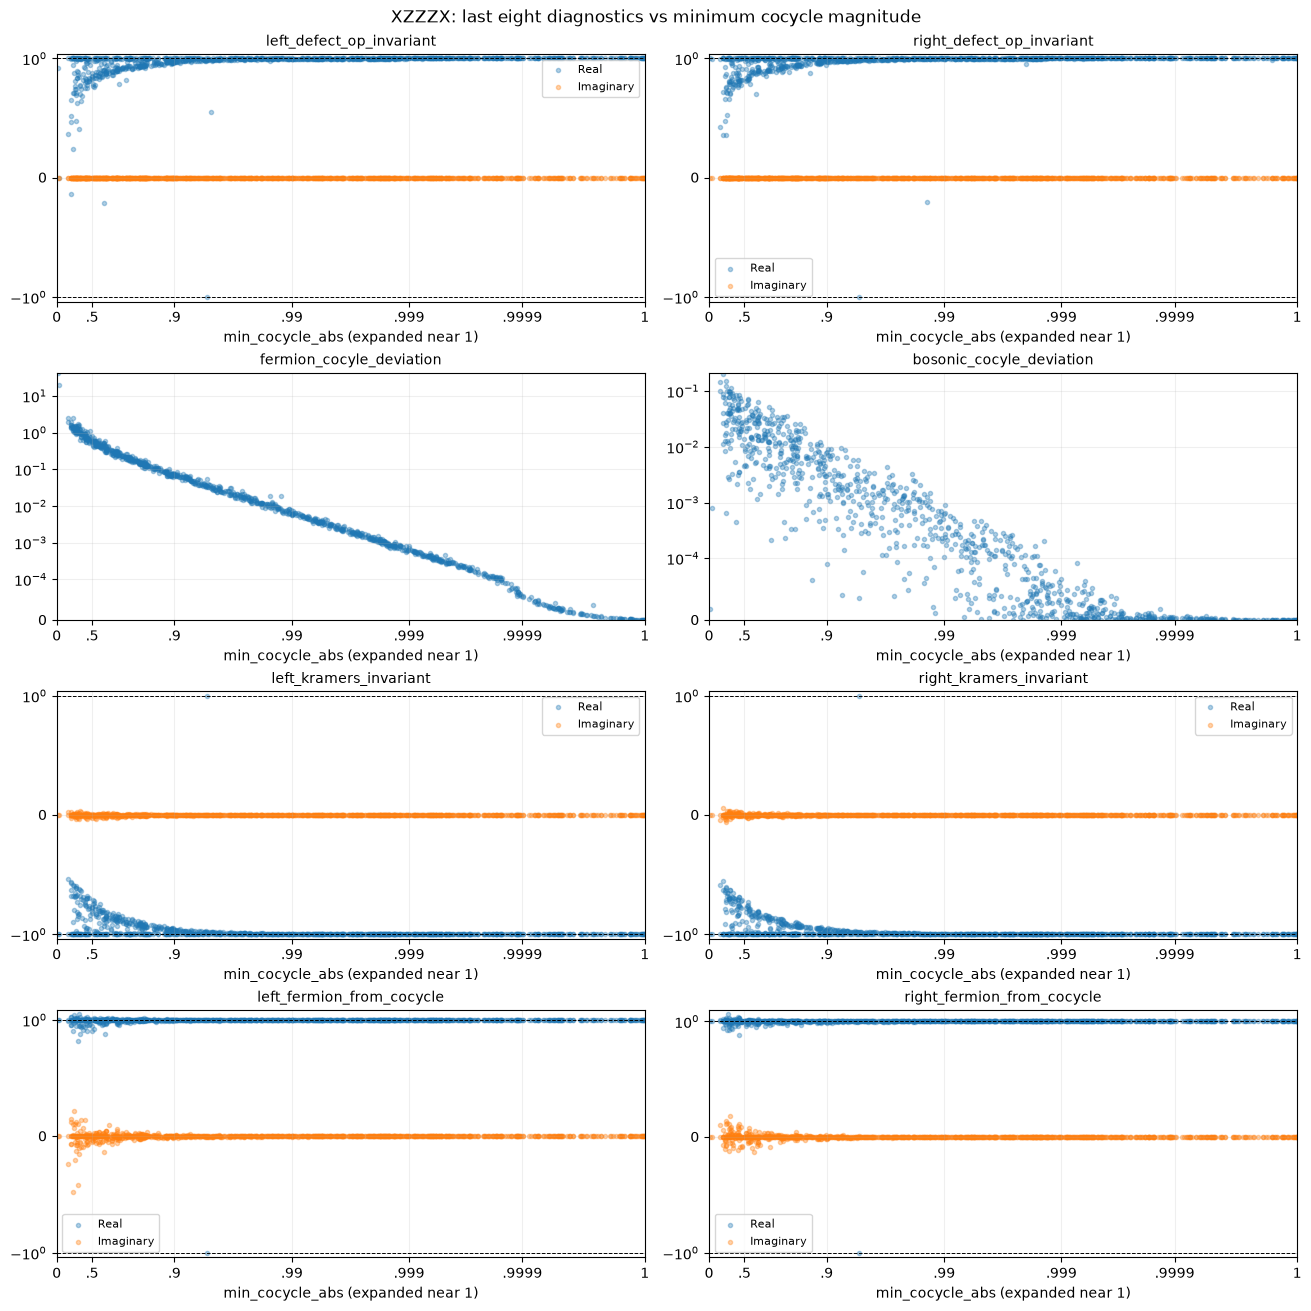

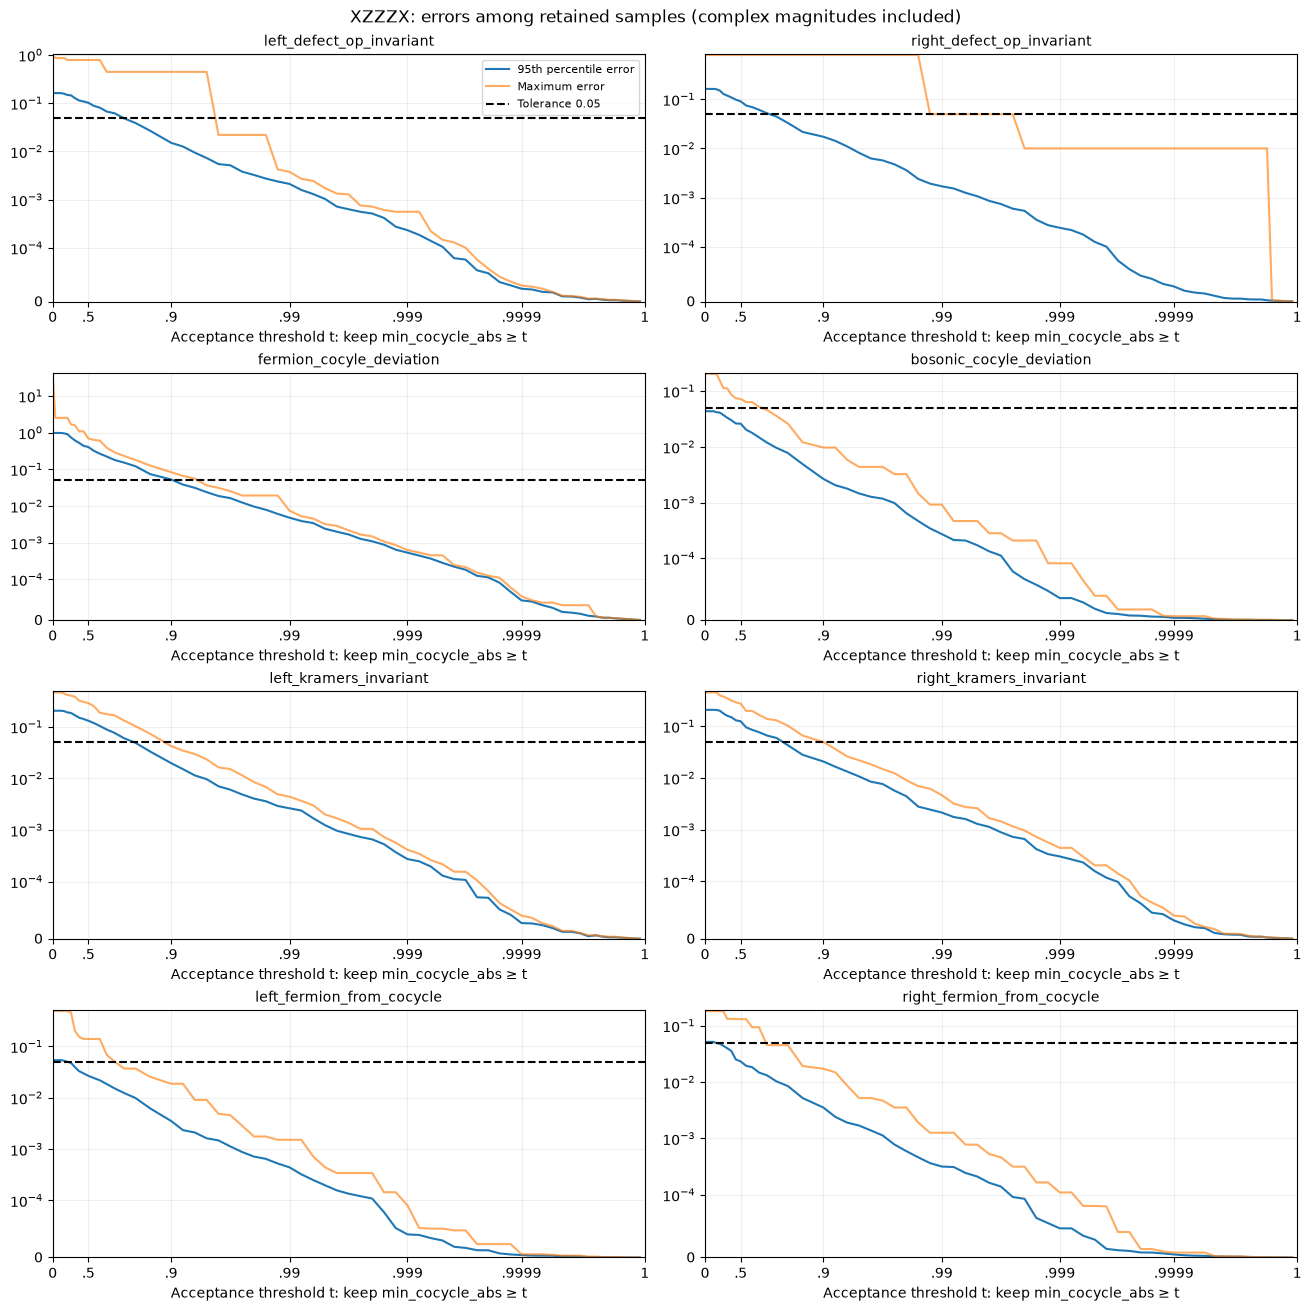

XZZZX: tolerance=0.05; require 95% of retained samples to pass all eight; at least 50 samples.
First qualifying tested threshold: 0.920567; retains 638/1000 samples. This is an empirical candidate, not a validated universal cutoff.
Default invariant errors measure distance to either ±1, not correctness of the SPT class. Supply targets={column: expected_sign} to test a known class.


,threshold,retained_n,retained_fraction,all_eight_pass_fraction,q95_max_error_across_eight,max_error_across_eight
0,0.000000,1000,1.000,0.624000,9.833513e-01,4.098804e+01
1,0.050000,998,0.998,0.625251,9.792509e-01,2.523635e+00
2,0.100000,998,0.998,0.625251,9.792509e-01,2.523635e+00
3,0.150000,998,0.998,0.625251,9.792509e-01,2.523635e+00
4,0.200000,996,0.996,0.626506,9.520858e-01,2.523635e+00
...,...,...,...,...,...,...
64,0.999997,14,0.014,1.000000,1.418692e-06,1.418692e-06
65,0.999998,12,0.012,1.000000,1.209852e-06,1.209852e-06
66,0.999998,10,0.010,1.000000,7.742086e-07,7.742086e-07
67,0.999999,10,0.010,1.000000,7.742086e-07,7.742086e-07


In [182]:
xzzzx_threshold_report = plot_diagnostic_dependence(
    xzzzx_diagnostics, "XZZZX", tolerance=0.05,
    required_pass_fraction=0.95, min_samples=50,
)
xzzzx_threshold_report

### Analyze results

#### Projector scores

In [183]:
np.round(np.array([
    d['left_proj_vec_results'][0][-1]
    for d in xzzzx_results
]), 3)

array([ 0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   ,  0.   ,  0.   ,
       -0.   , -0.   , -0.   , -0.   , -0.   ,  0.   ,  0.   ,  0.   ,
       -0.   , -0.   , -0.   ,  0.   ,  0.   ,  0.   , -0.   ,  0.   ,
        0.   , -0.   ,  0.   ,  0.   , -0.   , -0.   ,  0.   , -0.   ,
        0.   , -0.   ,  0.   , -0.   , -0.   ,  0.   ,  0.   ,  0.   ,
        0.   , -0.   ,  0.   ,  0.   ,  0.   , -0.   , -0.   , -0.   ,
        0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   , -0.   ,  0.   ,
        0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   , -0.   ,
       -0.   ,  0.   ,  0.   , -0.   ,  0.   ,  0.   , -0.   ,  0.   ,
        0.   ,  0.   , -0.   ,  0.   ,  0.   ,  0.   , -0.   ,  0.   ,
       -0.   , -0.   ,  0.   , -0.   , -0.   ,  0.   ,  0.   , -0.   ,
       -0.   , -0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   , -0.   ,
       -0.   , -0.   ,  0.   ,  0.   ,  0.   ,  0.   , -0.   ,  0.   ,
        0.   ,  0.   ,  0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
      

In [184]:
np.round(np.array([
    d['right_proj_vec_results'][0][-1]
    for d in xzzzx_results
]), 3)

array([-0.   , -0.   , -0.   ,  0.   , -0.   , -0.   , -0.   ,  0.   ,
        0.   ,  0.   , -0.   , -0.   ,  0.   ,  0.   , -0.   ,  0.   ,
        0.   , -0.   , -0.   , -0.   ,  0.   ,  0.   , -0.   ,  0.   ,
       -0.   ,  0.   , -0.   , -0.   ,  0.   , -0.   ,  0.   , -0.   ,
       -0.   ,  0.   , -0.   ,  0.   , -0.   , -0.   ,  0.   ,  0.   ,
       -0.   , -0.   ,  0.   ,  0.   ,  0.   , -0.   ,  0.   ,  0.   ,
        0.   , -0.   ,  0.   , -0.   , -0.   ,  0.   , -0.   ,  0.   ,
       -0.   ,  0.   , -0.   , -0.   , -0.   , -0.   , -0.   , -0.   ,
       -0.   ,  0.   ,  0.   , -0.   , -0.   ,  0.   ,  0.   ,  0.   ,
       -0.   ,  0.   ,  0.   ,  0.   , -0.   , -0.   , -0.   , -0.   ,
       -0.   , -0.   , -0.   , -0.   ,  0.   ,  0.   ,  0.   ,  0.   ,
       -0.   , -0.   , -0.   ,  0.   , -0.   , -0.   , -0.   ,  0.   ,
        0.   , -0.   ,  0.   , -0.   , -0.   , -0.   ,  0.   ,  0.   ,
        0.   , -0.   ,  0.   ,  0.   , -0.   ,  0.   , -0.   , -0.   ,
      

In [185]:
def get_schmidt_vals_ratio(schmidt_vals):
    if len(schmidt_vals.data) > 1:
        return schmidt_vals.data[1]/schmidt_vals.data[0]
    else:
        return 0

In [186]:
np.round(np.array([
    get_schmidt_vals_ratio(d['left_proj_vec_results'][1])
    for d in xzzzx_results
]), 3)

array([0.011, 0.002, 0.005, 0.001, 0.003, 0.001, 0.005, 0.001, 0.001,
       0.003, 0.002, 0.002, 0.002, 0.002, 0.003, 0.003, 0.003, 0.001,
       0.003, 0.005, 0.005, 0.005, 0.001, 0.003, 0.002, 0.   , 0.012,
       0.005, 0.   , 0.001, 0.002, 0.   , 0.002, 0.003, 0.003, 0.002,
       0.001, 0.001, 0.004, 0.003, 0.004, 0.005, 0.003, 0.003, 0.005,
       0.003, 0.   , 0.003, 0.003, 0.002, 0.005, 0.001, 0.003, 0.002,
       0.002, 0.001, 0.003, 0.008, 0.001, 0.005, 0.003, 0.005, 0.008,
       0.003, 0.002, 0.005, 0.005, 0.002, 0.003, 0.006, 0.002, 0.003,
       0.003, 0.004, 0.001, 0.002, 0.003, 0.004, 0.001, 0.002, 0.002,
       0.001, 0.003, 0.001, 0.001, 0.009, 0.003, 0.001, 0.003, 0.002,
       0.002, 0.004, 0.004, 0.002, 0.005, 0.002, 0.   , 0.005, 0.005,
       0.001, 0.006, 0.005, 0.002, 0.001, 0.003, 0.003, 0.011, 0.001,
       0.001, 0.004, 0.001, 0.002, 0.002, 0.002, 0.005, 0.003, 0.002,
       0.009, 0.004, 0.002, 0.002, 0.003, 0.002, 0.004, 0.002, 0.001,
       0.001, 0.002,

In [187]:
np.round(np.array([
    get_schmidt_vals_ratio(d['right_proj_vec_results'][1])
    for d in xzzzx_results
]), 3)

array([0.001, 0.002, 0.001, 0.002, 0.002, 0.001, 0.001, 0.003, 0.003,
       0.006, 0.004, 0.003, 0.003, 0.004, 0.   , 0.002, 0.004, 0.001,
       0.004, 0.002, 0.003, 0.002, 0.   , 0.002, 0.002, 0.002, 0.002,
       0.002, 0.004, 0.003, 0.003, 0.002, 0.002, 0.008, 0.001, 0.001,
       0.001, 0.001, 0.003, 0.002, 0.002, 0.004, 0.005, 0.003, 0.006,
       0.   , 0.004, 0.003, 0.004, 0.001, 0.005, 0.003, 0.002, 0.017,
       0.001, 0.002, 0.001, 0.003, 0.002, 0.001, 0.002, 0.001, 0.001,
       0.003, 0.002, 0.005, 0.004, 0.001, 0.003, 0.003, 0.003, 0.002,
       0.   , 0.003, 0.006, 0.004, 0.001, 0.001, 0.   , 0.002, 0.004,
       0.003, 0.   , 0.002, 0.002, 0.002, 0.004, 0.007, 0.   , 0.   ,
       0.002, 0.004, 0.001, 0.   , 0.001, 0.001, 0.003, 0.004, 0.005,
       0.001, 0.003, 0.001, 0.001, 0.003, 0.003, 0.002, 0.003, 0.003,
       0.001, 0.007, 0.004, 0.001, 0.   , 0.002, 0.001, 0.003, 0.003,
       0.001, 0.004, 0.002, 0.003, 0.001, 0.002, 0.004, 0.001, 0.005,
       0.   , 0.002,

#### Purities

In [188]:
np.round(np.array(
    [d['cut_rho_purity'] for d in xzzzx_results]
), 3)

array([0.543+0.j, 0.72 -0.j, 0.998+0.j, 0.688-0.j, 0.972-0.j, 0.909+0.j,
       0.381+0.j, 0.799+0.j, 0.922+0.j, 0.615+0.j, 0.988-0.j, 0.999-0.j,
       0.997+0.j, 0.901+0.j, 1.   +0.j, 0.915-0.j, 0.492+0.j, 0.992-0.j,
       0.999-0.j, 0.704+0.j, 0.528-0.j, 0.473+0.j, 0.679+0.j, 0.998+0.j,
       0.331+0.j, 0.506+0.j, 0.384+0.j, 0.829-0.j, 0.674-0.j, 0.637-0.j,
       0.536+0.j, 0.999-0.j, 0.589-0.j, 0.508+0.j, 0.999-0.j, 0.885+0.j,
       0.415-0.j, 0.252-0.j, 0.999-0.j, 0.766-0.j, 0.985-0.j, 0.899-0.j,
       0.494+0.j, 1.   +0.j, 0.821-0.j, 0.911-0.j, 0.943+0.j, 0.975-0.j,
       0.672-0.j, 0.986-0.j, 0.997+0.j, 0.561-0.j, 1.   -0.j, 0.598+0.j,
       0.333-0.j, 0.262+0.j, 0.554+0.j, 0.746+0.j, 0.94 +0.j, 0.834+0.j,
       0.743-0.j, 0.999+0.j, 0.825-0.j, 0.999+0.j, 0.991-0.j, 0.888-0.j,
       0.985+0.j, 0.613-0.j, 0.697-0.j, 0.956+0.j, 0.997+0.j, 0.875+0.j,
       0.899-0.j, 0.571-0.j, 0.367+0.j, 0.982+0.j, 0.997-0.j, 0.569+0.j,
       1.   -0.j, 0.558-0.j, 0.598+0.j, 0.958-0.j, 

In [189]:
np.round(np.array(
    [d['sub_cut_rho_trace'] for d in xzzzx_results]
), 3)

array([1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
      

In [190]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in xzzzx_results]
), 3)

array([0.543+0.j, 0.72 -0.j, 0.998+0.j, 0.688-0.j, 0.972-0.j, 0.909+0.j,
       0.381+0.j, 0.799+0.j, 0.922+0.j, 0.615+0.j, 0.988-0.j, 0.999-0.j,
       0.997+0.j, 0.901+0.j, 1.   +0.j, 0.915-0.j, 0.492+0.j, 0.992-0.j,
       0.999-0.j, 0.704+0.j, 0.528-0.j, 0.473+0.j, 0.679+0.j, 0.998+0.j,
       0.331+0.j, 0.506+0.j, 0.384+0.j, 0.829-0.j, 0.674-0.j, 0.637-0.j,
       0.536+0.j, 0.999-0.j, 0.589-0.j, 0.508+0.j, 0.999-0.j, 0.885+0.j,
       0.415-0.j, 0.252-0.j, 0.999-0.j, 0.766-0.j, 0.985-0.j, 0.899-0.j,
       0.494+0.j, 1.   +0.j, 0.821-0.j, 0.911-0.j, 0.943+0.j, 0.975-0.j,
       0.672-0.j, 0.986-0.j, 0.997+0.j, 0.561-0.j, 1.   -0.j, 0.598+0.j,
       0.333-0.j, 0.262+0.j, 0.554+0.j, 0.746+0.j, 0.94 +0.j, 0.834+0.j,
       0.743-0.j, 0.999+0.j, 0.825-0.j, 0.999+0.j, 0.991-0.j, 0.888-0.j,
       0.985+0.j, 0.613-0.j, 0.697-0.j, 0.956+0.j, 0.997+0.j, 0.875+0.j,
       0.899-0.j, 0.571-0.j, 0.367+0.j, 0.982+0.j, 0.997+0.j, 0.569+0.j,
       1.   -0.j, 0.558-0.j, 0.598+0.j, 0.958-0.j, 

Purities are the same, which one could likely prove.

In [191]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in xzzzx_results]
), 3)

array([0.543+0.j, 0.72 -0.j, 0.998+0.j, 0.688-0.j, 0.972-0.j, 0.909+0.j,
       0.381+0.j, 0.799+0.j, 0.922+0.j, 0.615+0.j, 0.988-0.j, 0.999-0.j,
       0.997+0.j, 0.901+0.j, 1.   +0.j, 0.915-0.j, 0.492+0.j, 0.992-0.j,
       0.999-0.j, 0.704+0.j, 0.528-0.j, 0.473+0.j, 0.679+0.j, 0.998+0.j,
       0.331+0.j, 0.506+0.j, 0.384+0.j, 0.829-0.j, 0.674-0.j, 0.637-0.j,
       0.536+0.j, 0.999-0.j, 0.589-0.j, 0.508+0.j, 0.999-0.j, 0.885+0.j,
       0.415-0.j, 0.252-0.j, 0.999-0.j, 0.766-0.j, 0.985-0.j, 0.899-0.j,
       0.494+0.j, 1.   +0.j, 0.821-0.j, 0.911-0.j, 0.943+0.j, 0.975-0.j,
       0.672-0.j, 0.986-0.j, 0.997+0.j, 0.561-0.j, 1.   -0.j, 0.598+0.j,
       0.333-0.j, 0.262+0.j, 0.554+0.j, 0.746+0.j, 0.94 +0.j, 0.834+0.j,
       0.743-0.j, 0.999+0.j, 0.825-0.j, 0.999+0.j, 0.991-0.j, 0.888-0.j,
       0.985+0.j, 0.613-0.j, 0.697-0.j, 0.956+0.j, 0.997+0.j, 0.875+0.j,
       0.899-0.j, 0.571-0.j, 0.367+0.j, 0.982+0.j, 0.997+0.j, 0.569+0.j,
       1.   -0.j, 0.558-0.j, 0.598+0.j, 0.958-0.j, 

#### Cut state results

In [192]:
np.array(
    [d['cut_state_fermion_parity'] for d in xzzzx_results]
)

array([ 1.        -2.32460464e-19j,  1.        +1.56496485e-19j,
        1.        +1.04237296e-19j,  1.        +1.13860549e-21j,
       -1.        +7.39393288e-20j, -1.        +5.54151529e-21j,
        0.99999986+5.35439546e-20j, -1.        +9.89453594e-20j,
        1.        -1.40682382e-20j,  1.        +1.44529772e-19j,
       -1.        -7.48364001e-20j, -1.        -9.64420450e-20j,
        1.        +1.11332604e-19j, -1.        -3.06662179e-20j,
        1.        +9.60631664e-20j, -1.        -9.41659110e-20j,
        0.13995616+1.38193030e-19j, -1.        +5.76448277e-20j,
        1.        +1.10766777e-19j, -1.        -1.01729243e-19j,
       -1.        +8.13070704e-20j,  0.99999989-7.67929457e-20j,
       -1.        +1.68327100e-19j, -1.        +5.09326257e-20j,
        0.9999863 -2.44481157e-20j, -0.99980536+2.47332793e-20j,
       -0.99999989+1.53166330e-19j,  1.        -7.58950972e-20j,
       -1.        +1.89671728e-19j, -1.        +2.49742545e-20j,
       -1.        +8.6968

In [193]:
np.round(np.array(
    [d['cut_overlap'] for d in xzzzx_results]
), 3)

array([1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   ,

#### Defect op scores overlaps

In [194]:
np.round(np.array([
    [d['defect_ops_scores'][i][-1] for d in xzzzx_results]
    for i in range(3)
]), 5)

array([[1.     , 1.     , 0.90113, ..., 1.     , 1.     , 0.99999],
       [1.     , 1.     , 1.     , ..., 1.     , 1.     , 1.     ],
       [1.     , 1.     , 0.90113, ..., 1.     , 1.     , 0.99999]],
      shape=(3, 1000))

#### Phases

In [195]:
xzzzx_left_phases = np.array([
    d['left_defect_op_invariant'] for d in xzzzx_results
])

In [196]:
xzzzx_left_phases.shape

(1000,)

In [197]:
np.round(xzzzx_left_phases, 3)

array([ 1.   +0.j,  0.943-0.j,  0.999-0.j,  0.986-0.j,  0.997-0.j,
        1.   +0.j,  1.   +0.j,  1.   -0.j,  1.   +0.j,  1.   +0.j,
        1.   -0.j,  1.   +0.j,  1.   +0.j,  0.999+0.j,  1.   +0.j,
        0.999-0.j,  0.999-0.j,  0.997+0.j,  1.   -0.j,  0.999+0.j,
        0.991-0.j,  0.994+0.j,  0.991+0.j,  1.   +0.j,  0.994-0.j,
        1.   +0.j,  0.819+0.j,  1.   -0.j,  0.91 +0.j,  1.   -0.j,
        0.996+0.j,  1.   -0.j,  0.998-0.j,  1.   +0.j,  1.   -0.j,
        1.   +0.j,  0.891-0.j,  0.978-0.j,  1.   -0.j,  0.988-0.j,
        0.999-0.j,  0.986+0.j,  0.711+0.j,  1.   +0.j,  0.998+0.j,
        1.   -0.j,  1.   +0.j,  1.   -0.j,  0.994-0.j,  1.   -0.j,
        1.   +0.j,  1.   +0.j,  1.   -0.j,  0.997-0.j,  1.   -0.j,
        1.   -0.j,  0.835-0.j,  1.   +0.j,  0.999+0.j,  1.   -0.j,
        0.999+0.j,  1.   +0.j,  0.996-0.j,  1.   +0.j,  1.   +0.j,
        0.962-0.j,  0.996-0.j,  1.   -0.j,  1.   +0.j,  1.   +0.j,
        0.999+0.j,  0.967+0.j,  0.999-0.j,  1.   -0.j,  0.799-

In [198]:
xzzzx_right_phases = np.array([
    d['right_defect_op_invariant'] for d in xzzzx_results
])

In [199]:
xzzzx_right_phases.shape

(1000,)

In [200]:
np.round(xzzzx_right_phases, 3)

array([ 1.   +0.j,  1.   -0.j,  1.   +0.j,  1.   -0.j,  0.995-0.j,
        1.   +0.j,  0.964-0.j,  0.999+0.j,  1.   +0.j,  1.   +0.j,
        1.   +0.j,  1.   -0.j,  1.   +0.j,  1.   +0.j,  1.   +0.j,
        0.979-0.j,  0.53 +0.j,  1.   +0.j,  1.   -0.j,  1.   +0.j,
        0.999-0.j,  0.806-0.j,  1.   +0.j,  1.   -0.j,  1.   -0.j,
        0.887-0.j,  1.   +0.j,  0.958-0.j,  1.   +0.j,  1.   -0.j,
        0.999+0.j,  1.   -0.j,  1.   -0.j,  0.998+0.j,  1.   -0.j,
        0.999+0.j,  0.93 -0.j,  0.999-0.j,  1.   -0.j,  0.998-0.j,
        1.   +0.j,  0.976+0.j,  0.997+0.j,  1.   +0.j,  1.   -0.j,
        1.   -0.j,  0.998+0.j,  0.995+0.j,  0.964-0.j,  1.   -0.j,
        1.   +0.j,  0.893+0.j,  1.   -0.j,  0.876+0.j,  0.784-0.j,
        0.999-0.j,  1.   -0.j,  0.974+0.j,  1.   +0.j,  1.   +0.j,
        0.923+0.j,  1.   +0.j,  1.   -0.j,  1.   +0.j,  0.998+0.j,
        1.   -0.j,  1.   -0.j,  0.998+0.j,  0.882+0.j,  0.999+0.j,
        1.   +0.j,  1.   +0.j,  1.   -0.j,  0.996-0.j,  1.   -

#### Cocyle information

In [201]:
xzzzx_cocycle_equation_array = np.array([d['cocycle_equation_output'] for d in xzzzx_results])
print(np.linalg.norm(xzzzx_cocycle_equation_array-1))
print(np.max(np.abs(xzzzx_cocycle_equation_array-1)))

115.03453930966526
40.98804350579164


In [202]:
xzzzx_bosonic_cocycle_equation_array = np.array([d['bosonic_cocycle_equation_output'] for d in xzzzx_results])

In [203]:
xzzzx_bosonic_cocycle_equation_array.shape

(1000, 2, 2, 2, 2)

In [204]:
np.linalg.norm(xzzzx_bosonic_cocycle_equation_array-1)

np.float64(0.6544423771782034)

In [205]:
xzzzx_results[0]['cocycles'].shape

(2, 2, 2, 2, 2)

In [206]:
np.round(
    np.array([d['cocycles'][:, 0,1,0,1] for d in xzzzx_results])
, 3)

array([[-1.   +0.j   , -1.   +0.j   ],
       [-0.927+0.002j, -1.   +0.j   ],
       [-0.999+0.j   , -1.   +0.j   ],
       ...,
       [-1.   -0.j   , -1.   -0.j   ],
       [-0.981-0.002j, -0.918-0.008j],
       [-1.   -0.j   , -1.   -0.j   ]], shape=(1000, 2))

In [207]:
np.round(
    np.array([d['fermion_decoration_from_cocycle'] for d in xzzzx_results])
, 3)

array([[1.   -0.j   , 1.   +0.j   ],
       [0.963+0.049j, 1.   -0.j   ],
       [1.   +0.j   , 1.   -0.j   ],
       ...,
       [1.   -0.j   , 1.   +0.j   ],
       [0.992+0.026j, 0.999+0.008j],
       [1.   +0.j   , 1.   -0.j   ]], shape=(1000, 2))

# Interpretation

The product-state near-zero anomaly was a dataset mix-up caused by out-of-order execution and shared globals. The separate XZX data really do contain small cocycles, including high-purity/high-overlap runs; the product-state correction does not resolve that separate extraction problem.

High cut purity and high joint defect overlap alone do not establish independent boundary actions. For example, the normalized saved XZX cut state at sample 864 has $\|\rho_{LR}-\rho_L\otimes\rho_R\|_F \approx 0.302585$, whereas the tested product samples give values of order $10^{-16}$. In addition, `gauge_fix_cocycles` uses the magnitudes of imperfect cocycles in its gauge factors, so it can shrink or amplify them; a true U(1) gauge transformation preserves magnitudes. Do not interpret the resulting tiny values or large cocycle-equation ratios as reliable topological invariants.


In [208]:
def boundary_connected_norm(record):
    # The same dominant cut state used to fit the saved defect operators.
    state = record['cut_state']
    sites = sorted(state.inds, key=lambda ind: int(ind[1:]))
    left_dim = record['left_defect_ops'][0].shape[0]
    right_dim = record['right_defect_ops'][0].shape[0]
    amplitudes = state.transpose(*sites).data.reshape(left_dim, -1, right_dim)
    amplitudes = amplitudes / np.linalg.norm(amplitudes)
    rho_lr = np.einsum('amc,bmd->acbd', amplitudes, amplitudes.conj())
    rho_lr = rho_lr.reshape(left_dim * right_dim, left_dim * right_dim)
    rho_l = np.einsum('amc,bmc->ab', amplitudes, amplitudes.conj())
    rho_r = np.einsum('amc,amd->cd', amplitudes, amplitudes.conj())
    return np.linalg.norm(rho_lr - np.kron(rho_l, rho_r))

pd.DataFrame([
    {'dataset': label, 'sample': sample,
     'boundary_connected_norm': boundary_connected_norm(records[sample]),
     **summarize_saved_results([records[sample]]).iloc[0].to_dict()}
    for label, records in [('product', product_results), ('xzx', xzx_results)]
    for sample in [91, 216, 864]
])


,dataset,sample,boundary_connected_norm,min_cocycle_abs,min_defect_overlap,cut_purity,sub_cut_purity,left_defect_op_invariant,right_defect_op_invariant,fermion_cocyle_deviation,bosonic_cocyle_deviation,left_kramers_invariant,right_kramers_invariant,left_fermion_from_cocycle,right_fermion_from_cocycle
0,product,91,6.809632e-16,0.999967+0.000000j,1.0+0.0j,0.999967+0.000000j,0.999967+0.000000j,1.000000-0.000000j,0.999988-0.000000j,2.622631e-05+0.000000e+00j,3.373770e-06+0.000000e+00j,1.000000-0.000000j,0.999992-0.000002j,1.000000+0.000000j,1.000005+0.000004j
1,product,216,7.160370e-16,1.000000+0.000000j,1.0+0.0j,0.999999+0.000000j,0.999999+0.000000j,1.000000+0.000000j,1.000000-0.000000j,2.323882e-07+0.000000e+00j,3.990312e-08+0.000000e+00j,1.000000-0.000000j,1.000000-0.000000j,1.000000+0.000000j,1.000000+0.000000j
2,product,864,7.803374e-16,0.999998+0.000000j,1.0+0.0j,0.999998+0.000000j,0.999998+0.000000j,1.000000-0.000000j,1.000000+0.000000j,1.558060e-06+0.000000e+00j,1.323050e-07+0.000000e+00j,1.000000+0.000000j,1.000000+0.000000j,1.000000+0.000000j,1.000000+0.000000j
3,xzx,91,3.881863e-16,0.999997+0.000000j,1.0+0.0j,0.999997+0.000000j,0.999997+0.000000j,-0.999999+0.000000j,-1.000000+0.000000j,1.926081e-06+0.000000e+00j,8.202469e-08+0.000000e+00j,0.999999+0.000000j,1.000000-0.000000j,-1.000000+0.000000j,-1.000000+0.000000j
4,xzx,216,3.787187e-16,0.999973+0.000000j,1.0+0.0j,0.999968+0.000000j,0.999968+0.000000j,-0.999991+0.000000j,-0.999998+0.000000j,1.947319e-05+0.000000e+00j,4.675437e-07+0.000000e+00j,0.999989+0.000000j,0.999998+0.000000j,-1.000002-0.000002j,-1.000000-0.000000j
5,xzx,864,5.978281e-16,0.999993+0.000000j,1.0+0.0j,0.999993+0.000000j,0.999993+0.000000j,-1.000000+0.000000j,-0.999998-0.000000j,5.031883e-06+0.000000e+00j,3.042101e-07+0.000000e+00j,1.000000+0.000000j,0.999997-0.000000j,-1.000000-0.000000j,-1.000000-0.000000j


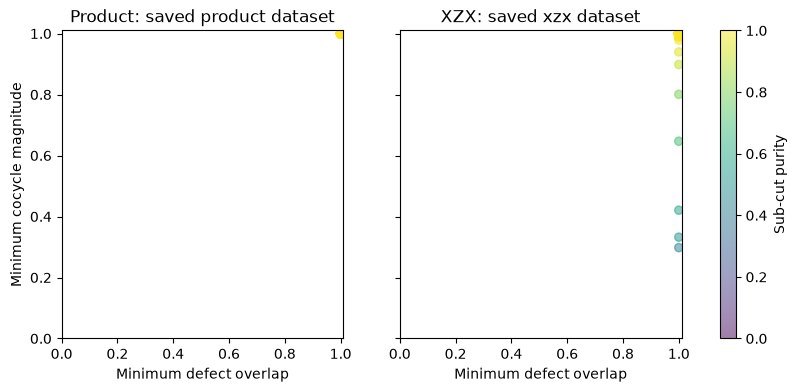

In [209]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, label, diagnostics in zip(
    axes, ['Product', 'XZX'], [product_diagnostics, xzx_diagnostics]
):
    points = ax.scatter(diagnostics['min_defect_overlap'],
                        diagnostics['min_cocycle_abs'],
                        c=diagnostics['sub_cut_purity'], vmin=0, vmax=1,
                        alpha=0.5)
    ax.set_title(f'{label}: saved {label.lower()} dataset')
    ax.set_xlabel('Minimum defect overlap')
    ax.set_xlim(0, 1.01)
    ax.set_ylim(0, 1.01)
axes[0].set_ylabel('Minimum cocycle magnitude')
fig.colorbar(points, ax=axes, label='Sub-cut purity')
plt.show()
